# TechNova Partners : identifier les causes d'attrition

**Contexte.** TechNova Partners (ESN) constate un taux de démission plus élevé que d'habitude. Le responsable SIRH
(Augustin Moser) nous a transmis trois extraits de données ; Amandine Rousset (Manager Data Scientist) attend :

1. une **analyse exploratoire** qui fait ressortir les différences entre les employés partis et les autres ;
2. un **modèle de classification** qui score la probabilité de démission ;
3. une **interprétation** du modèle avec SHAP (importance globale et locale) pour en tirer des causes potentielles.

**Plan du notebook**

| Partie | Contenu |
|---|---|
| 0 | Imports et réglages |
| 1 | Chargement, nettoyage, jointure, analyse exploratoire |
| 2 | Préparation des features : X et y |
| 3 | Premiers modèles : Dummy, linéaire, non linéaire |
| 4 | Déséquilibre des classes : stratification, validation croisée, seuil |
| 5 | Fine-tuning et interprétation (feature importance globale et locale) |
| 6 | Synthèse |

Chaque étape récurrente est encapsulée dans une fonction pour pouvoir la rejouer à l'identique.

## 0. Imports et réglages

In [1]:
# Manipulation des données
from pathlib import Path

import numpy as np
import pandas as pd

# Graphiques
import matplotlib.pyplot as plt
import seaborn as sns

# Modélisation (scikit-learn)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_predict,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    PrecisionRecallDisplay,
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
)
from sklearn.inspection import permutation_importance

# Rééquilibrage des classes (imbalanced-learn)
from imblearn.pipeline import Pipeline as PipelineImb
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# Interprétabilité
import shap

import warnings
# Le modèle Dummy ne prédit jamais la classe 1 : sa précision est indéfinie (comptée 0).
# On masque cet avertissement attendu.
warnings.filterwarnings("ignore", message="Precision is ill-defined")

# Réglages communs
GRAINE = 42                      # graine aléatoire : résultats reproductibles
DOSSIER_DONNEES = Path("data")
DOSSIER_FIGURES = Path("figures")
DOSSIER_FIGURES.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 60)
COULEURS = {"Reste": "#4C72B0", "Parti": "#DD8452"}


def sauver(fig, nom):
    """Enregistre une figure dans figures/ (réutilisée dans la présentation)."""
    fig.savefig(DOSSIER_FIGURES / f"{nom}.png", dpi=150, bbox_inches="tight")

## 1. Chargement, nettoyage, jointure et analyse exploratoire

### 1.1 Chargement des trois fichiers

In [2]:
sirh = pd.read_csv(DOSSIER_DONNEES / "extrait_sirh.csv")
evaluation = pd.read_csv(DOSSIER_DONNEES / "extrait_eval.csv")
sondage = pd.read_csv(DOSSIER_DONNEES / "extrait_sondage.csv")

for nom, df in {"SIRH": sirh, "Évaluations": evaluation, "Sondage": sondage}.items():
    print(f"{nom:12s} : {df.shape[0]} lignes, {df.shape[1]} colonnes, "
          f"{df.duplicated().sum()} doublon(s), {df.isna().sum().sum()} valeur(s) manquante(s)")

SIRH         : 1470 lignes, 12 colonnes, 0 doublon(s), 0 valeur(s) manquante(s)
Évaluations  : 1470 lignes, 10 colonnes, 0 doublon(s), 0 valeur(s) manquante(s)
Sondage      : 1470 lignes, 12 colonnes, 0 doublon(s), 0 valeur(s) manquante(s)


In [3]:
sirh.head()

,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,nombre_heures_travailless,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,80,8,6,4
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,80,10,10,7
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,80,7,0,0
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,80,8,8,7
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,80,6,2,2


In [4]:
evaluation.head()

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,eval_number,note_evaluation_actuelle,heure_supplementaires,augementation_salaire_precedente
0,2,3,2,4,1,1,E_1,3,Oui,11 %
1,3,2,2,2,4,3,E_2,4,Non,23 %
2,4,2,1,3,2,3,E_4,3,Oui,15 %
3,4,3,1,3,3,3,E_5,3,Oui,11 %
4,1,3,1,2,4,3,E_7,3,Non,12 %


In [5]:
sondage.head()

,a_quitte_l_entreprise,nombre_participation_pee,nb_formations_suivies,nombre_employee_sous_responsabilite,code_sondage,distance_domicile_travail,niveau_education,domaine_etude,ayant_enfants,frequence_deplacement,annees_depuis_la_derniere_promotion,annes_sous_responsable_actuel
0,Oui,0,0,1,1,1,2,Infra & Cloud,Y,Occasionnel,0,5
1,Non,1,3,1,2,8,1,Infra & Cloud,Y,Frequent,1,7
2,Oui,0,3,1,4,2,2,Autre,Y,Occasionnel,0,0
3,Non,0,3,1,5,3,4,Infra & Cloud,Y,Frequent,3,0
4,Non,1,3,1,7,2,1,Transformation Digitale,Y,Occasionnel,2,2


### 1.2 Comprendre les colonnes avant d'analyser

On regarde le type, le nombre de valeurs distinctes et quelques exemples pour chaque colonne : cela permet de
séparer les colonnes **quantitatives** des colonnes **qualitatives** et de repérer celles qui demandent un nettoyage.

In [6]:
def decrire_colonnes(df):
    """Résumé d'un DataFrame : type, nombre de valeurs distinctes et exemples, colonne par colonne."""
    return pd.DataFrame({
        "type": df.dtypes.astype(str),
        "nb_valeurs_distinctes": df.nunique(),
        "exemples": df.apply(lambda col: list(col.unique()[:5])),
    })


decrire_colonnes(sirh)

,type,nb_valeurs_distinctes,exemples
id_employee,int64,1470,"[1, 2, 4, 5, 7]"
age,int64,43,"[41, 49, 37, 33, 27]"
genre,str,2,"[F, M]"
revenu_mensuel,int64,1349,"[5993, 5130, 2090, 2909, 3468]"
statut_marital,str,3,"[Célibataire, Marié(e), Divorcé(e)]"
departement,str,3,"[Commercial, Consulting, Ressources Humaines]"
poste,str,9,"[Cadre Commercial, Assistant de Direction, Con..."
nombre_experiences_precedentes,int64,10,"[8, 1, 6, 9, 0]"
nombre_heures_travailless,int64,1,[80]
annee_experience_totale,int64,40,"[8, 10, 7, 6, 12]"


In [7]:
decrire_colonnes(evaluation)

,type,nb_valeurs_distinctes,exemples
satisfaction_employee_environnement,int64,4,"[2, 3, 4, 1]"
note_evaluation_precedente,int64,4,"[3, 2, 4, 1]"
niveau_hierarchique_poste,int64,5,"[2, 1, 3, 4, 5]"
satisfaction_employee_nature_travail,int64,4,"[4, 2, 3, 1]"
satisfaction_employee_equipe,int64,4,"[1, 4, 2, 3]"
satisfaction_employee_equilibre_pro_perso,int64,4,"[1, 3, 2, 4]"
eval_number,str,1470,"[E_1, E_2, E_4, E_5, E_7]"
note_evaluation_actuelle,int64,2,"[3, 4]"
heure_supplementaires,str,2,"[Oui, Non]"
augementation_salaire_precedente,str,15,"[11 %, 23 %, 15 %, 12 %, 13 %]"


In [8]:
decrire_colonnes(sondage)

,type,nb_valeurs_distinctes,exemples
a_quitte_l_entreprise,str,2,"[Oui, Non]"
nombre_participation_pee,int64,4,"[0, 1, 3, 2]"
nb_formations_suivies,int64,7,"[0, 3, 2, 5, 1]"
nombre_employee_sous_responsabilite,int64,1,[1]
code_sondage,int64,1470,"[1, 2, 4, 5, 7]"
distance_domicile_travail,int64,29,"[1, 8, 2, 3, 24]"
niveau_education,int64,5,"[2, 1, 4, 3, 5]"
domaine_etude,str,6,"[Infra & Cloud, Autre, Transformation Digitale..."
ayant_enfants,str,1,[Y]
frequence_deplacement,str,3,"[Occasionnel, Frequent, Aucun]"


**Constats**

- Aucune valeur manquante ni doublon dans les trois fichiers (1 470 employés chacun).
- Trois colonnes sont **constantes** et n'apportent aucune information : `nombre_heures_travailless` (toujours 80),
  `nombre_employee_sous_responsabilite` (toujours 1) et `ayant_enfants` (toujours « Y »). On les supprimera.
- `augementation_salaire_precedente` est stockée en texte (« 11 % ») : à convertir en nombre.
- `heure_supplementaires` et la cible `a_quitte_l_entreprise` sont en « Oui / Non » : à convertir en 1 / 0.
- Les notes de satisfaction et d'évaluation (1 à 4) et le niveau d'éducation (1 à 5) sont des **qualitatives ordinales**
  déjà codées dans le bon ordre.
- **Clés de jointure** : `id_employee` (SIRH), `eval_number` (« E_1 » → 1) et `code_sondage` (1, 2, …).

### 1.3 Nettoyage colonne par colonne (avec `.apply()`)

In [9]:
def pourcentage_en_nombre(valeur):
    """'11 %' -> 11 (entier)."""
    return int(str(valeur).replace("%", "").strip())


def oui_non_en_binaire(valeur):
    """'Oui' -> 1, 'Non' -> 0."""
    return 1 if valeur == "Oui" else 0


def numero_evaluation_en_id(valeur):
    """'E_12' -> 12 : rend la clé du fichier d'évaluation comparable à id_employee."""
    return int(valeur.replace("E_", ""))


def nettoyer_sirh(df):
    df = df.copy()
    return df.drop(columns=["nombre_heures_travailless"])  # constante (80)


def nettoyer_evaluation(df):
    df = df.copy()
    df["id_employee"] = df["eval_number"].apply(numero_evaluation_en_id)
    df["augmentation_salaire_precedente"] = df["augementation_salaire_precedente"].apply(pourcentage_en_nombre)
    df["heures_supplementaires"] = df["heure_supplementaires"].apply(oui_non_en_binaire)
    # On supprime les colonnes d'origine (noms avec fautes de frappe) et la clé texte devenue inutile
    return df.drop(columns=["eval_number", "augementation_salaire_precedente", "heure_supplementaires"])


def nettoyer_sondage(df):
    df = df.copy()
    df["id_employee"] = df["code_sondage"]
    df["a_quitte"] = df["a_quitte_l_entreprise"].apply(oui_non_en_binaire)
    df = df.rename(columns={"annes_sous_responsable_actuel": "annees_sous_responsable_actuel"})
    # Colonnes constantes ou redondantes avec la clé
    return df.drop(columns=["code_sondage", "a_quitte_l_entreprise",
                            "nombre_employee_sous_responsabilite", "ayant_enfants"])


sirh_propre = nettoyer_sirh(sirh)
evaluation_propre = nettoyer_evaluation(evaluation)
sondage_propre = nettoyer_sondage(sondage)
evaluation_propre.head(3)

,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,id_employee,augmentation_salaire_precedente,heures_supplementaires
0,2,3,2,4,1,1,3,1,11,1
1,3,2,2,2,4,3,4,2,23,0
2,4,2,1,3,2,3,3,4,15,1


### 1.4 Statistiques descriptives simples sur chaque fichier

In [10]:
sirh_propre.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
id_employee,1470.0,1024.9,602.0,1.0,491.2,1020.5,1555.8,2068.0
age,1470.0,36.9,9.1,18.0,30.0,36.0,43.0,60.0
revenu_mensuel,1470.0,6502.9,4708.0,1009.0,2911.0,4919.0,8379.0,19999.0
nombre_experiences_precedentes,1470.0,2.7,2.5,0.0,1.0,2.0,4.0,9.0
annee_experience_totale,1470.0,11.3,7.8,0.0,6.0,10.0,15.0,40.0
annees_dans_l_entreprise,1470.0,7.0,6.1,0.0,3.0,5.0,9.0,40.0
annees_dans_le_poste_actuel,1470.0,4.2,3.6,0.0,2.0,3.0,7.0,18.0


In [11]:
evaluation_propre.drop(columns='id_employee').describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
satisfaction_employee_environnement,1470.0,2.72,1.09,1.0,2.0,3.0,4.0,4.0
note_evaluation_precedente,1470.0,2.73,0.71,1.0,2.0,3.0,3.0,4.0
niveau_hierarchique_poste,1470.0,2.06,1.11,1.0,1.0,2.0,3.0,5.0
satisfaction_employee_nature_travail,1470.0,2.73,1.10,1.0,2.0,3.0,4.0,4.0
satisfaction_employee_equipe,1470.0,2.71,1.08,1.0,2.0,3.0,4.0,4.0
satisfaction_employee_equilibre_pro_perso,1470.0,2.76,0.71,1.0,2.0,3.0,3.0,4.0
note_evaluation_actuelle,1470.0,3.15,0.36,3.0,3.0,3.0,3.0,4.0
augmentation_salaire_precedente,1470.0,15.21,3.66,11.0,12.0,14.0,18.0,25.0
heures_supplementaires,1470.0,0.28,0.45,0.0,0.0,0.0,1.0,1.0


In [12]:
sondage_propre.drop(columns='id_employee').describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
nombre_participation_pee,1470.0,0.79,0.85,0.0,0.0,1.0,1.0,3.0
nb_formations_suivies,1470.0,2.80,1.29,0.0,2.0,3.0,3.0,6.0
distance_domicile_travail,1470.0,9.19,8.11,1.0,2.0,7.0,14.0,29.0
niveau_education,1470.0,2.91,1.02,1.0,2.0,3.0,4.0,5.0
annees_depuis_la_derniere_promotion,1470.0,2.19,3.22,0.0,0.0,1.0,3.0,15.0
annees_sous_responsable_actuel,1470.0,4.12,3.57,0.0,2.0,3.0,7.0,17.0
a_quitte,1470.0,0.16,0.37,0.0,0.0,0.0,0.0,1.0


In [13]:
# Variables qualitatives : répartition des modalités
for colonne in ["genre", "statut_marital", "departement", "poste"]:
    print(sirh_propre[colonne].value_counts().to_string(), "\n")
for colonne in ["domaine_etude", "frequence_deplacement"]:
    print(sondage_propre[colonne].value_counts().to_string(), "\n")

genre
M    882
F    588 

statut_marital
Marié(e)       673
Célibataire    470
Divorcé(e)     327 

departement
Consulting             961
Commercial             446
Ressources Humaines     63 

poste
Cadre Commercial           326
Assistant de Direction     292
Consultant                 259
Tech Lead                  145
Manager                    131
Senior Manager             102
Représentant Commercial     83
Directeur Technique         80
Ressources Humaines         52 

domaine_etude
Infra & Cloud              606
Transformation Digitale    464
Marketing                  159
Entrepreunariat            132
Autre                       82
Ressources Humaines         27 

frequence_deplacement
Occasionnel    1043
Frequent        277
Aucun           150 



### 1.5 Jointure des trois fichiers : le DataFrame central

Chaque fichier contient exactement une ligne par employé et les trois clés désignent les mêmes 1 470 identifiants.
On vérifie cette correspondance, puis on fait une **jointure interne** (`inner`) : elle ne garde que les employés
présents partout. Ici elle ne perd aucune ligne, mais elle garantit qu'aucun employé n'aurait une partie de ses
données manquante si un fichier était incomplet. `validate="one_to_one"` fait échouer la jointure s'il y avait un doublon.

In [14]:
ids_sirh = set(sirh_propre["id_employee"])
print("Mêmes employés dans SIRH et évaluations :", ids_sirh == set(evaluation_propre["id_employee"]))
print("Mêmes employés dans SIRH et sondage     :", ids_sirh == set(sondage_propre["id_employee"]))

df_central = (
    sirh_propre
    .merge(evaluation_propre, on="id_employee", how="inner", validate="one_to_one")
    .merge(sondage_propre, on="id_employee", how="inner", validate="one_to_one")
)
print("DataFrame central :", df_central.shape)
df_central.head()

Mêmes employés dans SIRH et évaluations : True
Mêmes employés dans SIRH et sondage     : True
DataFrame central : (1470, 29)


,id_employee,age,genre,revenu_mensuel,statut_marital,departement,poste,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,niveau_hierarchique_poste,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,augmentation_salaire_precedente,heures_supplementaires,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,domaine_etude,frequence_deplacement,annees_depuis_la_derniere_promotion,annees_sous_responsable_actuel,a_quitte
0,1,41,F,5993,Célibataire,Commercial,Cadre Commercial,8,8,6,4,2,3,2,4,1,1,3,11,1,0,0,1,2,Infra & Cloud,Occasionnel,0,5,1
1,2,49,M,5130,Marié(e),Consulting,Assistant de Direction,1,10,10,7,3,2,2,2,4,3,4,23,0,1,3,8,1,Infra & Cloud,Frequent,1,7,0
2,4,37,M,2090,Célibataire,Consulting,Consultant,6,7,0,0,4,2,1,3,2,3,3,15,1,0,3,2,2,Autre,Occasionnel,0,0,1
3,5,33,F,2909,Marié(e),Consulting,Assistant de Direction,1,8,8,7,4,3,1,3,3,3,3,11,1,0,3,3,4,Infra & Cloud,Frequent,3,0,0
4,7,27,M,3468,Marié(e),Consulting,Consultant,9,6,2,2,1,3,1,2,4,3,3,12,0,1,3,2,1,Transformation Digitale,Occasionnel,2,2,0


### 1.6 Différences entre les employés partis et les autres

Taux d'attrition : 16.1% (237 départs sur 1470 employés)


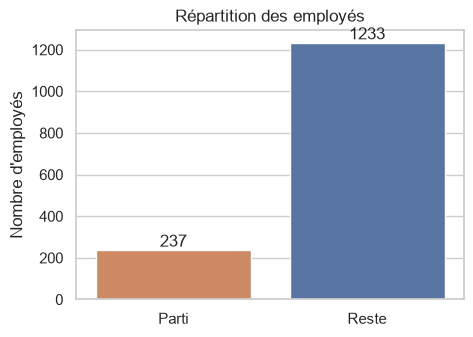

In [15]:
# Taux d'attrition global
taux = df_central["a_quitte"].mean()
print(f"Taux d'attrition : {taux:.1%} ({df_central['a_quitte'].sum()} départs sur {len(df_central)} employés)")

df_central["statut"] = df_central["a_quitte"].map({0: "Reste", 1: "Parti"})

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df_central, x="statut", hue="statut", palette=COULEURS, ax=ax, legend=False)
ax.set(title="Répartition des employés", xlabel="", ylabel="Nombre d'employés")
for barre in ax.patches:
    ax.annotate(f"{barre.get_height():.0f}", (barre.get_x() + barre.get_width() / 2, barre.get_height()),
                ha="center", va="bottom")
sauver(fig, "01_repartition_cible")
plt.show()

Les classes sont **déséquilibrées** (environ 1 départ pour 5 présents) : il faudra en tenir compte dans la modélisation.

**Variables quantitatives : moyennes et médianes par population**

In [16]:
variables_quanti = [
    "age", "revenu_mensuel", "nombre_experiences_precedentes", "annee_experience_totale",
    "annees_dans_l_entreprise", "annees_dans_le_poste_actuel", "annees_depuis_la_derniere_promotion",
    "annees_sous_responsable_actuel", "distance_domicile_travail", "augmentation_salaire_precedente",
    "nb_formations_suivies", "nombre_participation_pee",
]

moyennes = df_central.groupby("statut")[variables_quanti].mean().T
medianes = df_central.groupby("statut")[variables_quanti].median().T
comparaison = pd.DataFrame({
    "moyenne_reste": moyennes["Reste"], "moyenne_parti": moyennes["Parti"],
    "mediane_reste": medianes["Reste"], "mediane_parti": medianes["Parti"],
})
comparaison["ecart_moyenne_%"] = (comparaison["moyenne_parti"] / comparaison["moyenne_reste"] - 1) * 100
comparaison.round(1).sort_values("ecart_moyenne_%")

,moyenne_reste,moyenne_parti,mediane_reste,mediane_parti,ecart_moyenne_%
nombre_participation_pee,0.8,0.5,1.0,0.0,-37.6
annees_dans_le_poste_actuel,4.5,2.9,3.0,2.0,-35.3
annees_sous_responsable_actuel,4.4,2.9,3.0,2.0,-34.7
annee_experience_totale,11.9,8.2,10.0,7.0,-30.5
annees_dans_l_entreprise,7.4,5.1,6.0,3.0,-30.4
revenu_mensuel,6832.7,4787.1,5204.0,3202.0,-29.9
annees_depuis_la_derniere_promotion,2.2,1.9,1.0,1.0,-12.9
age,37.6,33.6,36.0,32.0,-10.5
nb_formations_suivies,2.8,2.6,3.0,2.0,-7.4
augmentation_salaire_precedente,15.2,15.1,14.0,14.0,-0.9


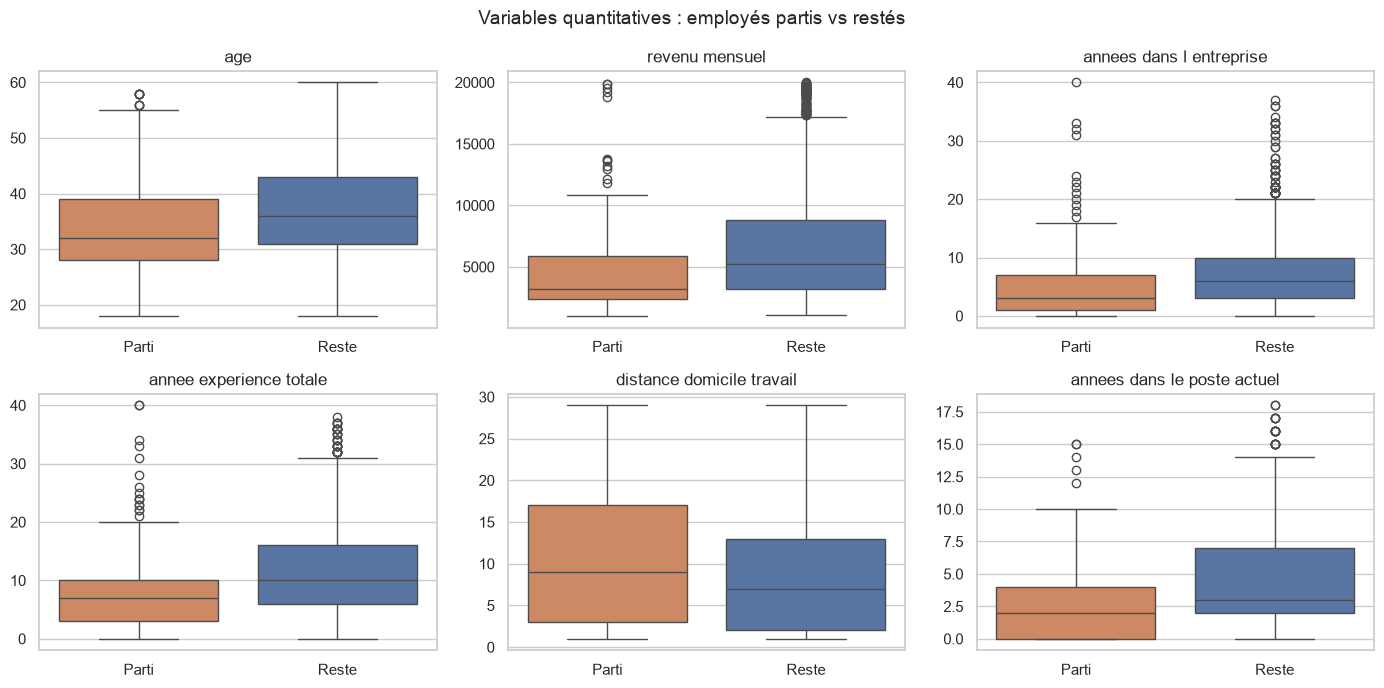

In [17]:
# Distribution des principales variables quantitatives : quanti vs quali -> boîtes à moustaches
a_tracer = ["age", "revenu_mensuel", "annees_dans_l_entreprise", "annee_experience_totale",
            "distance_domicile_travail", "annees_dans_le_poste_actuel"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, variable in zip(axes.flat, a_tracer):
    sns.boxplot(data=df_central, x="statut", y=variable, hue="statut", palette=COULEURS, ax=ax, legend=False)
    ax.set(title=variable.replace("_", " "), xlabel="", ylabel="")
fig.suptitle("Variables quantitatives : employés partis vs restés", fontsize=14)
fig.tight_layout()
sauver(fig, "02_boxplots_quanti")
plt.show()

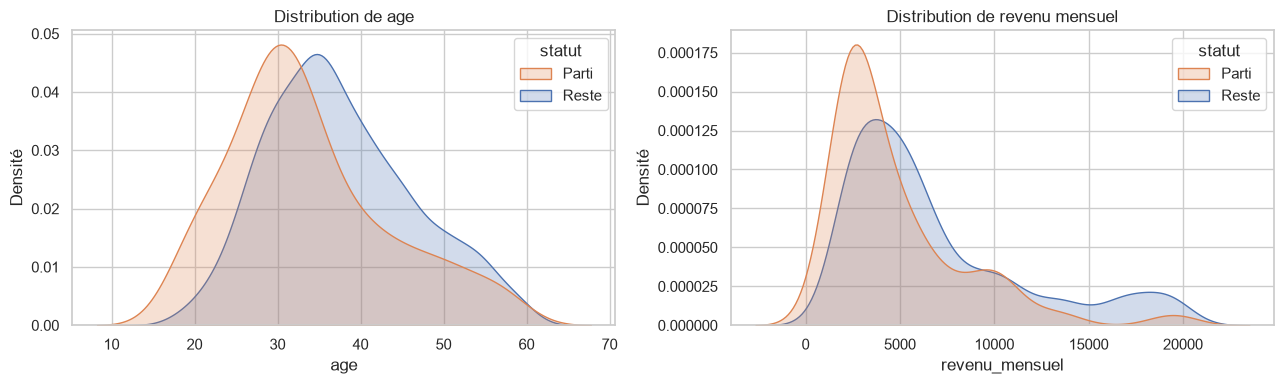

In [18]:
# Densités : âge et revenu (les deux différences les plus parlantes)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, variable in zip(axes, ["age", "revenu_mensuel"]):
    sns.kdeplot(data=df_central, x=variable, hue="statut", palette=COULEURS, common_norm=False, fill=True, ax=ax)
    ax.set(title=f"Distribution de {variable.replace('_', ' ')}", ylabel="Densité")
fig.tight_layout()
sauver(fig, "03_densites_age_revenu")
plt.show()

**Variables qualitatives : taux d'attrition par modalité** (quali vs quali → diagramme en barres de taux)

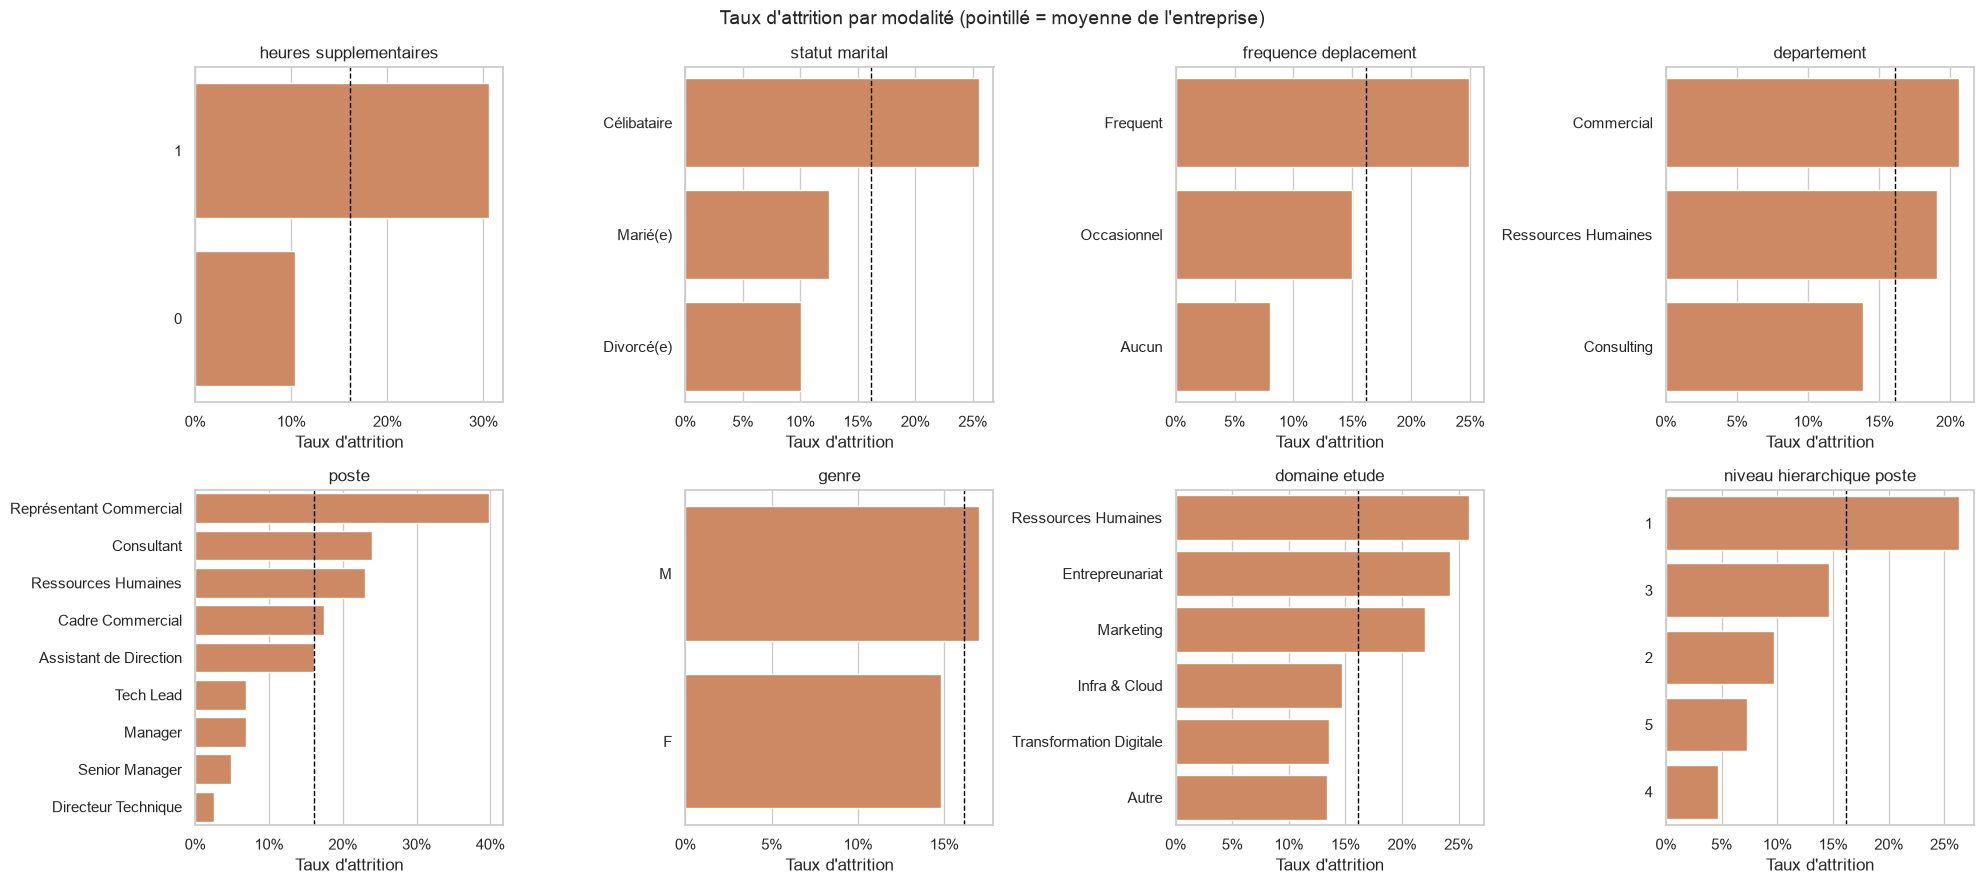

In [19]:
def taux_attrition_par(df, colonne):
    """Taux de départ et effectif pour chaque modalité d'une colonne."""
    return (df.groupby(colonne)["a_quitte"]
              .agg(taux_attrition="mean", effectif="size")
              .sort_values("taux_attrition", ascending=False))


variables_quali = ["heures_supplementaires", "statut_marital", "frequence_deplacement", "departement",
                   "poste", "genre", "domaine_etude", "niveau_hierarchique_poste"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, variable in zip(axes.flat, variables_quali):
    resume = taux_attrition_par(df_central, variable).reset_index()
    resume[variable] = resume[variable].astype(str)
    sns.barplot(data=resume, y=variable, x="taux_attrition", color="#DD8452", ax=ax)
    ax.axvline(taux, color="black", linestyle="--", linewidth=1, label="moyenne")
    ax.set(title=variable.replace("_", " "), xlabel="Taux d'attrition", ylabel="")
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Taux d'attrition par modalité (pointillé = moyenne de l'entreprise)", fontsize=14)
fig.tight_layout()
sauver(fig, "04_taux_par_modalite")
plt.show()

In [20]:
taux_attrition_par(df_central, 'heures_supplementaires')

,taux_attrition,effectif
heures_supplementaires,,
1,0.305288,416
0,0.104364,1054


In [21]:
taux_attrition_par(df_central, 'poste')

,taux_attrition,effectif
poste,,
Représentant Commercial,0.397590,83
Consultant,0.239382,259
Ressources Humaines,0.230769,52
Cadre Commercial,0.174847,326
Assistant de Direction,0.160959,292
Tech Lead,0.068966,145
Manager,0.068702,131
Senior Manager,0.049020,102
Directeur Technique,0.025000,80


**Notes de satisfaction et d'évaluation** (qualitatives ordinales)

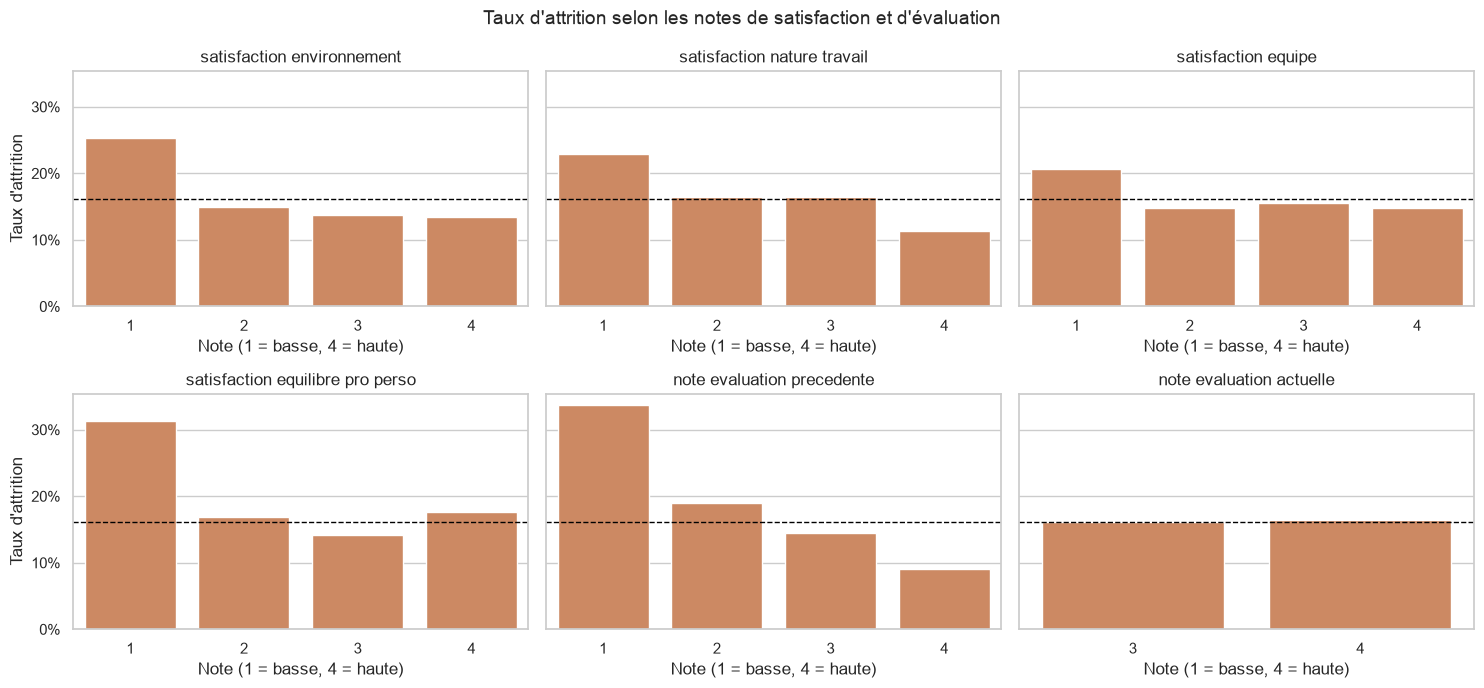

In [22]:
variables_satisfaction = [
    "satisfaction_employee_environnement", "satisfaction_employee_nature_travail",
    "satisfaction_employee_equipe", "satisfaction_employee_equilibre_pro_perso",
    "note_evaluation_precedente", "note_evaluation_actuelle",
]
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, variable in zip(axes.flat, variables_satisfaction):
    resume = taux_attrition_par(df_central, variable).reset_index()
    sns.barplot(data=resume, x=variable, y="taux_attrition", color="#DD8452", ax=ax)
    ax.axhline(taux, color="black", linestyle="--", linewidth=1)
    ax.set(title=variable.replace("satisfaction_employee_", "satisfaction ").replace("_", " "),
           xlabel="Note (1 = basse, 4 = haute)", ylabel="Taux d'attrition")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.suptitle("Taux d'attrition selon les notes de satisfaction et d'évaluation", fontsize=14)
fig.tight_layout()
sauver(fig, "05_satisfaction")
plt.show()

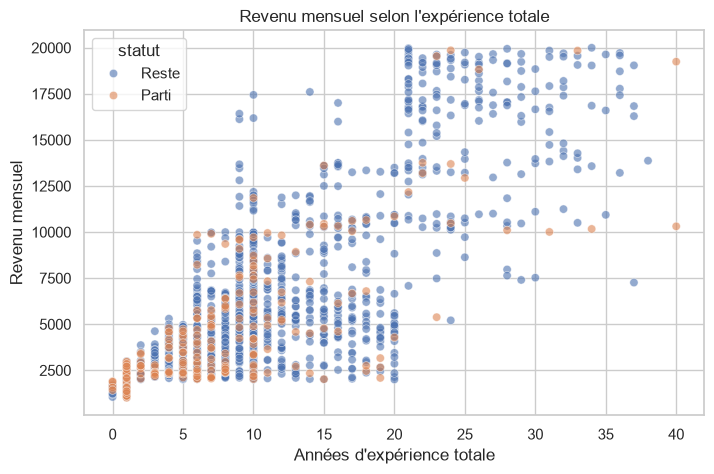

In [23]:
# Quanti vs quanti : ancienneté et revenu, coloré par statut
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df_central.sort_values("a_quitte"), x="annee_experience_totale", y="revenu_mensuel",
                hue="statut", palette=COULEURS, alpha=0.6, ax=ax)
ax.set(title="Revenu mensuel selon l'expérience totale", xlabel="Années d'expérience totale",
       ylabel="Revenu mensuel")
sauver(fig, "06_revenu_experience")
plt.show()

**Insights clés de l'analyse exploratoire**

1. **Heures supplémentaires** : c'est l'écart le plus net. Environ 30 % des employés qui font des heures
   supplémentaires sont partis, contre environ 10 % des autres.
2. **Jeunesse et faible ancienneté** : les partants sont plus jeunes (médiane ≈ 32 ans contre 36), ont moins
   d'expérience et moins d'ancienneté ; beaucoup partent dans les deux premières années.
3. **Rémunération** : le revenu médian des partants est nettement plus bas (≈ 3 200 contre ≈ 5 200), en lien avec
   un niveau hiérarchique plus bas (le niveau 1 concentre les départs).
4. **Postes** : les *Représentants Commerciaux* (≈ 40 %), les *Ressources Humaines* et les *Consultants*
   dépassent nettement la moyenne ; les postes de direction partent peu.
5. **Vie personnelle et déplacements** : célibataires et grands voyageurs partent plus souvent ; la distance
   domicile-travail est un peu plus grande chez les partants.
6. **Satisfaction** : une note de 1 (environnement, nature du travail, équipe, équilibre pro/perso) est associée
   à un taux de départ nettement supérieur. Les notes d'évaluation, elles, ne distinguent pas les deux populations.

Ces constats sont des **corrélations**, pas des causes : le modèle et SHAP serviront à les hiérarchiser
« toutes choses égales par ailleurs ».

## 2. Préparation des features : X et y

### 2.1 Création de features
On ajoute quelques variables métier calculées à partir des colonnes existantes :

| Feature | Calcul | Idée métier |
|---|---|---|
| `part_carriere_dans_entreprise` | ancienneté / expérience totale | fidélité à l'entreprise |
| `ratio_poste_entreprise` | années dans le poste / ancienneté | mobilité interne |
| `stagnation_promotion` | années depuis la promotion / ancienneté | sentiment de stagnation |
| `satisfaction_moyenne` | moyenne des 4 notes de satisfaction | satisfaction globale |
| `revenu_par_niveau` | revenu / niveau hiérarchique | rémunération à niveau égal |

Les ratios utilisent `+ 1` au dénominateur pour éviter les divisions par zéro (ancienneté de 0 an).

In [24]:
def creer_features(df):
    """Ajoute les features métier calculées au DataFrame central."""
    df = df.copy()
    df["part_carriere_dans_entreprise"] = df["annees_dans_l_entreprise"] / (df["annee_experience_totale"] + 1)
    df["ratio_poste_entreprise"] = df["annees_dans_le_poste_actuel"] / (df["annees_dans_l_entreprise"] + 1)
    df["stagnation_promotion"] = df["annees_depuis_la_derniere_promotion"] / (df["annees_dans_l_entreprise"] + 1)
    df["satisfaction_moyenne"] = df[[
        "satisfaction_employee_environnement", "satisfaction_employee_nature_travail",
        "satisfaction_employee_equipe", "satisfaction_employee_equilibre_pro_perso",
    ]].mean(axis=1)
    df["revenu_par_niveau"] = df["revenu_mensuel"] / df["niveau_hierarchique_poste"]
    return df


df_features = creer_features(df_central)
df_features.iloc[:3, -5:]

,part_carriere_dans_entreprise,ratio_poste_entreprise,stagnation_promotion,satisfaction_moyenne,revenu_par_niveau
0,0.666667,0.571429,0.000000,2.0,2996.5
1,0.909091,0.636364,0.090909,3.0,2565.0
2,0.000000,0.000000,0.000000,3.0,2090.0


### 2.2 Encodage des variables qualitatives

Le choix dépend du **sens métier** de chaque variable :

- **Binaire** (2 modalités) → 0 / 1 : `genre` (1 = homme), `heures_supplementaires` (déjà converti).
- **Ordinale** (ordre naturel) → entiers dans l'ordre : `frequence_deplacement` (Aucun = 0 < Occasionnel = 1 < Frequent = 2).
  Les notes de satisfaction, d'évaluation, le niveau d'éducation et le niveau hiérarchique sont déjà des entiers ordonnés.
- **Nominale** (aucun ordre) → **One-Hot** : `statut_marital`, `departement`, `poste`, `domaine_etude`.
  Un encodage ordinal inventerait un ordre qui n'existe pas (« Consultant < Manager » n'a pas de sens numérique).

L'encodage se fait avec un dictionnaire fixe et `pd.get_dummies` : il ne s'ajuste pas sur les données,
donc il n'y a pas de fuite d'information entre apprentissage et test.

In [25]:
ORDRE_DEPLACEMENT = {"Aucun": 0, "Occasionnel": 1, "Frequent": 2}
VARIABLES_NOMINALES = ["statut_marital", "departement", "poste", "domaine_etude"]


def encoder(df):
    """Encode les variables qualitatives selon leur nature (binaire, ordinale, nominale)."""
    df = df.copy()
    df["genre"] = df["genre"].apply(lambda g: 1 if g == "M" else 0)
    df["frequence_deplacement"] = df["frequence_deplacement"].map(ORDRE_DEPLACEMENT)
    df = pd.get_dummies(df, columns=VARIABLES_NOMINALES, dtype=int)
    return df


df_encode = encoder(df_features)
df_encode.shape

(1470, 52)

### 2.3 Corrélations : repérer les redondances

La matrice de **Pearson** mesure les liens **linéaires** ; on la calcule sur les variables numériques (quantitatives,
ordinales et binaires, pas sur les colonnes One-Hot d'une même variable qui sont liées par construction).
La matrice de **Spearman** (sur les rangs) capte aussi les liens **monotones non linéaires**.

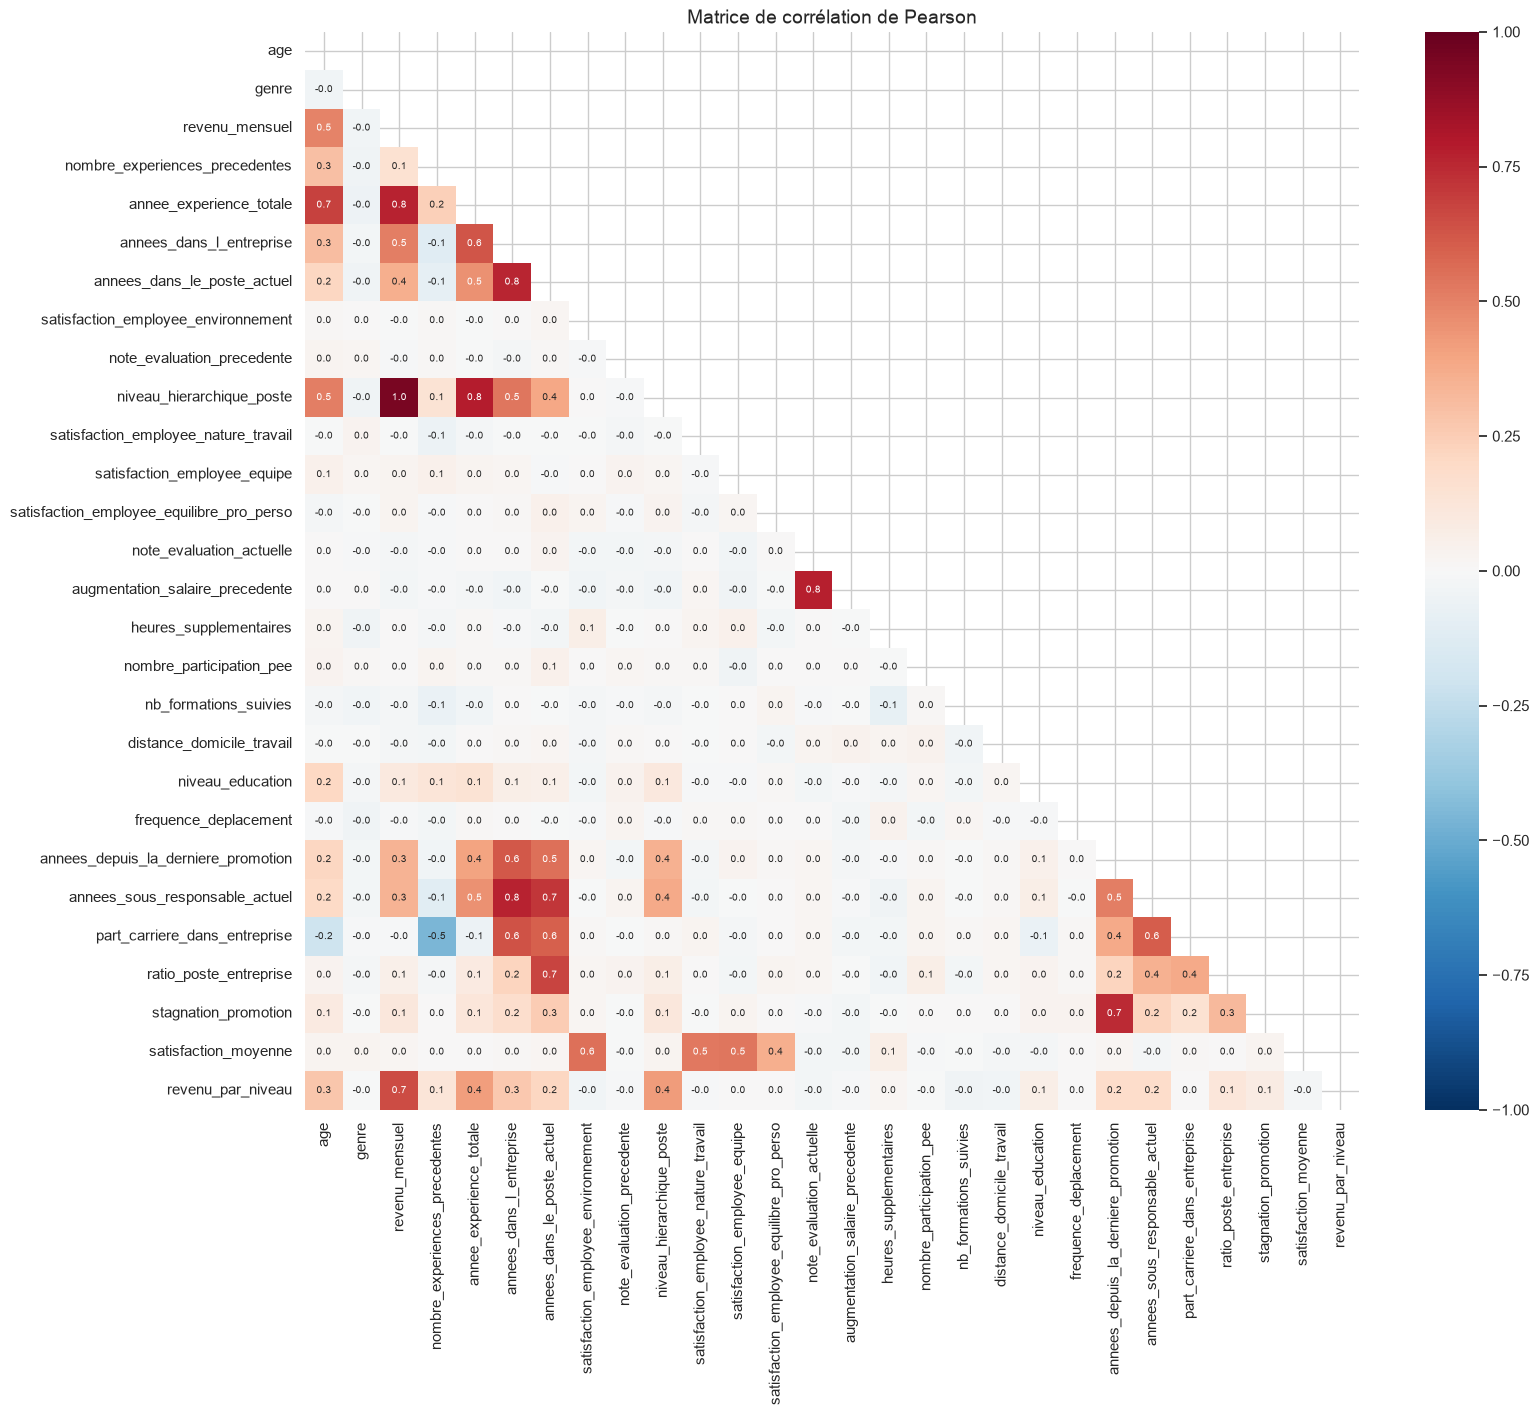

In [26]:
colonnes_numeriques = [c for c in df_encode.columns
                       if not c.startswith(tuple(VARIABLES_NOMINALES))
                       and c not in ("id_employee", "a_quitte", "statut")]
pearson = df_encode[colonnes_numeriques].corr(method="pearson")

fig, ax = plt.subplots(figsize=(17, 14))
masque = np.triu(np.ones_like(pearson, dtype=bool))
sns.heatmap(pearson, mask=masque, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("Matrice de corrélation de Pearson", fontsize=14)
sauver(fig, "07_pearson")
plt.show()

In [27]:
def paires_tres_correlees(matrice, seuil=0.7):
    """Liste les paires de variables dont la corrélation absolue dépasse le seuil."""
    haut = matrice.where(np.triu(np.ones(matrice.shape, dtype=bool), k=1))
    paires = haut.stack().rename("correlation").reset_index()
    return paires[paires["correlation"].abs() >= seuil].sort_values("correlation", key=abs, ascending=False)


paires_tres_correlees(pearson)

,level_0,level_1,correlation
65,revenu_mensuel,niveau_hierarchique_poste,0.950300
121,annee_experience_totale,niveau_hierarchique_poste,0.782208
378,note_evaluation_actuelle,augmentation_salaire_precedente,0.773550
60,revenu_mensuel,annee_experience_totale,0.772893
162,annees_dans_l_entreprise,annees_sous_responsable_actuel,0.769212
146,annees_dans_l_entreprise,annees_dans_le_poste_actuel,0.758754
613,annees_depuis_la_derniere_promotion,stagnation_promotion,0.744830
190,annees_dans_le_poste_actuel,annees_sous_responsable_actuel,0.714365


In [28]:
spearman = df_encode[colonnes_numeriques].corr(method="spearman")
paires_tres_correlees(spearman)

,level_0,level_1,correlation
613,annees_depuis_la_derniere_promotion,stagnation_promotion,0.936884
65,revenu_mensuel,niveau_hierarchique_poste,0.920429
146,annees_dans_l_entreprise,annees_dans_le_poste_actuel,0.854000
162,annees_dans_l_entreprise,annees_sous_responsable_actuel,0.842803
163,annees_dans_l_entreprise,part_carriere_dans_entreprise,0.767330
192,annees_dans_le_poste_actuel,ratio_poste_entreprise,0.752691
121,annee_experience_totale,niveau_hierarchique_poste,0.734678
190,annees_dans_le_poste_actuel,annees_sous_responsable_actuel,0.724754
60,revenu_mensuel,annee_experience_totale,0.710024


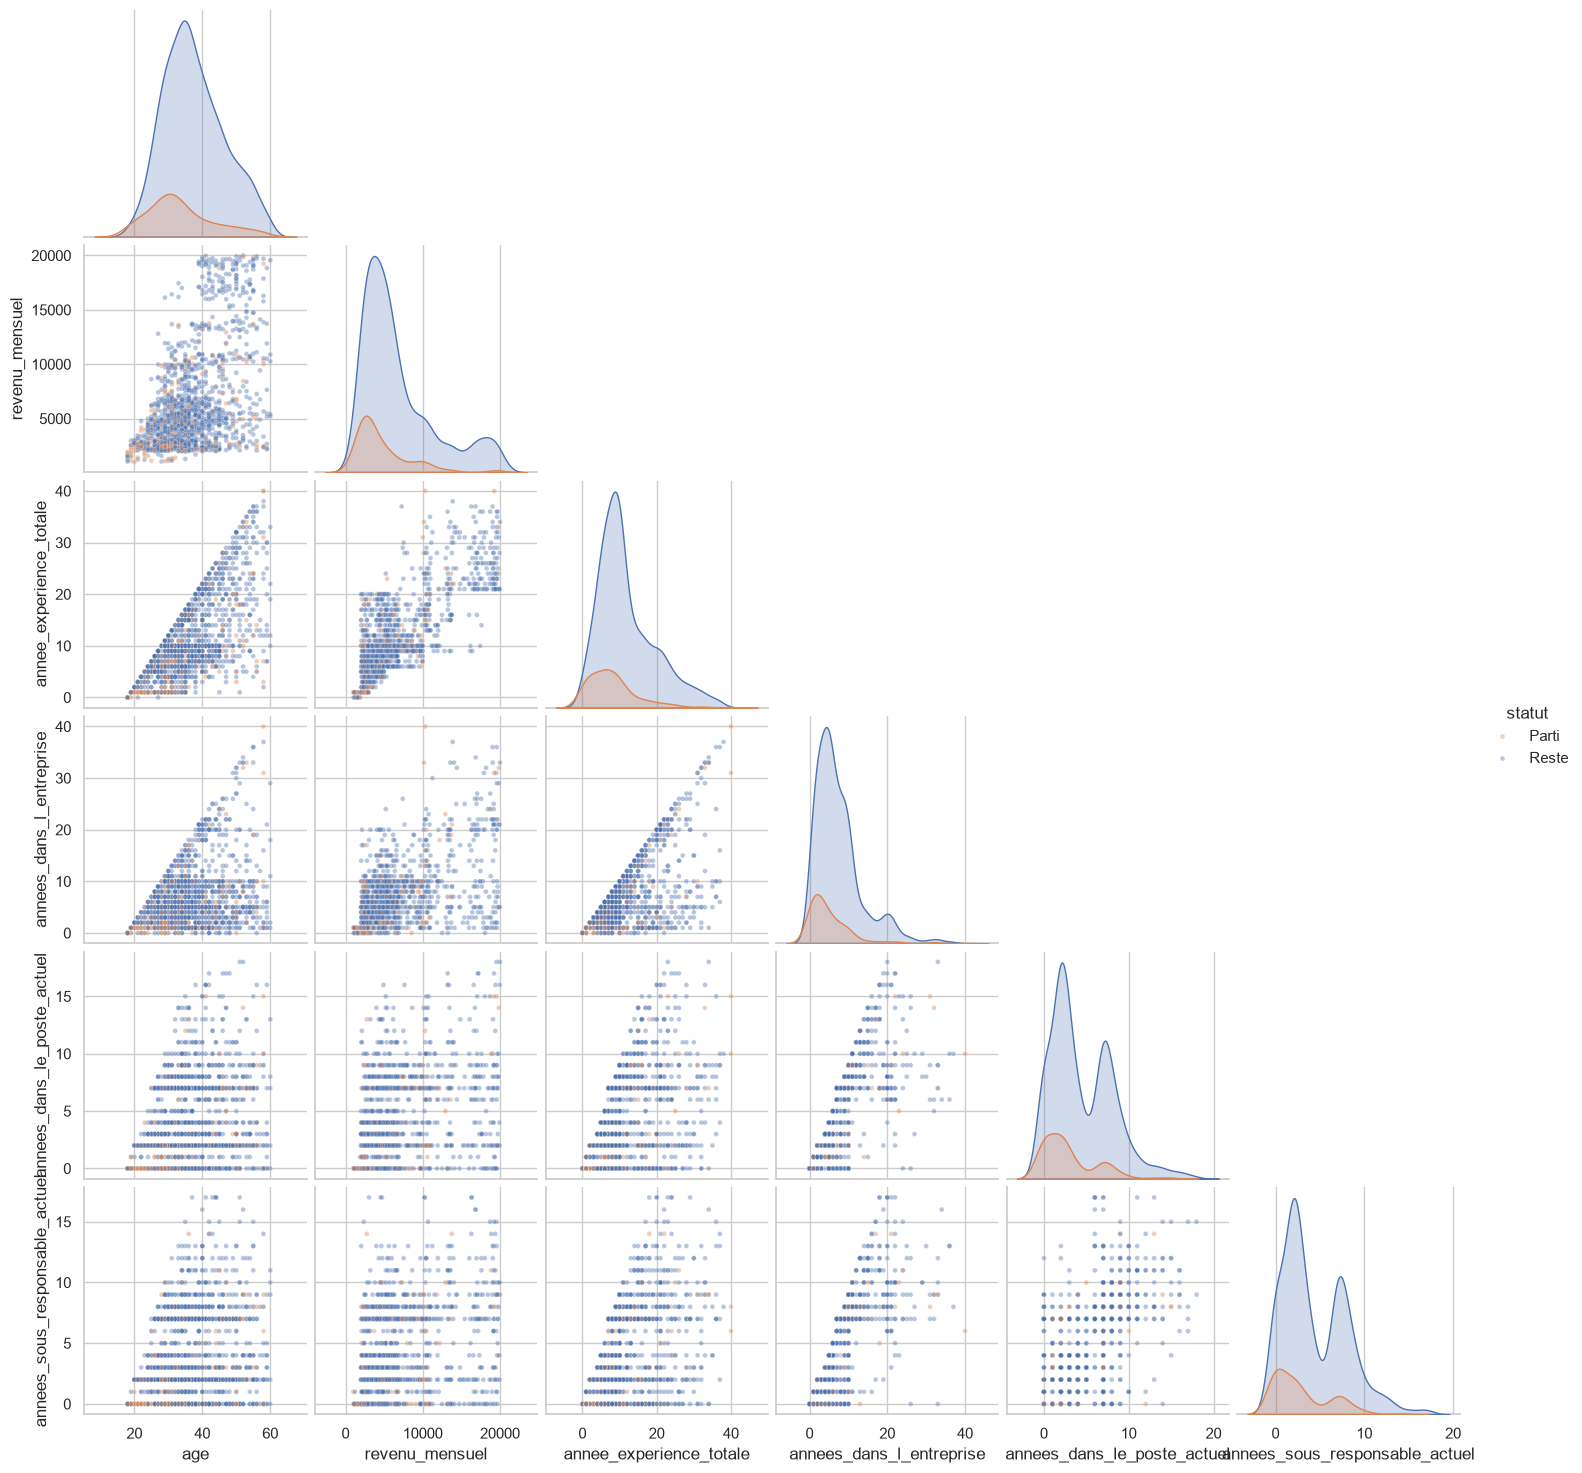

In [29]:
# Pairplot sur les variables les plus liées entre elles (liens non linéaires éventuels)
pairplot = sns.pairplot(
    df_features[["age", "revenu_mensuel", "annee_experience_totale", "annees_dans_l_entreprise",
                 "annees_dans_le_poste_actuel", "annees_sous_responsable_actuel", "statut"]],
    hue="statut", palette=COULEURS, plot_kws={"alpha": 0.4, "s": 12}, corner=True,
)
pairplot.savefig(DOSSIER_FIGURES / "08_pairplot.png", dpi=110)
plt.show()

**Décisions sur les redondances (seuil |r| ≥ 0,8)**

- `niveau_hierarchique_poste` et `revenu_mensuel` (r ≈ 0,95) : quasi la même information. On garde
  `revenu_mensuel` (plus fin) et la feature `revenu_par_niveau`, on retire `niveau_hierarchique_poste`.
- `satisfaction_moyenne` est construite à partir des 4 notes : on garde les 4 notes détaillées (plus interprétables)
  et on retire la moyenne.
- `annees_dans_l_entreprise`, `annees_dans_le_poste_actuel` et `annees_sous_responsable_actuel` sont fortement liées
  (r ≈ 0,77) mais restent sous le seuil et portent des informations différentes (mobilité interne, management) : on les garde.
- `annee_experience_totale` est liée au revenu et au niveau (r ≈ 0,77-0,78) et `annees_depuis_la_derniere_promotion`
  à la feature `stagnation_promotion` (r ≈ 0,74, 0,94 en Spearman) : sous le seuil de Pearson, et les arbres
  tolèrent bien ces corrélations. On les garde, en sachant qu'elles se « partageront » l'importance.
- `note_evaluation_actuelle` et `augmentation_salaire_precedente` (r ≈ 0,77) : logique (l'augmentation dépend de la
  note), mais aucune des deux ne distingue les partants ; on les garde, le modèle leur donnera peu de poids.
- Le One-Hot de `departement` est presque déduit de `poste` (chaque poste, sauf Senior Manager, appartient à un seul
  département) : on retire les colonnes `departement_*`.

Le pairplot montre des liens surtout linéaires ou monotones (déjà captés par Pearson / Spearman), pas de relation
non linéaire forte cachée.

In [30]:
COLONNES_A_RETIRER = [
    "id_employee", "statut", "a_quitte",                      # identifiant, libellé, cible
    "niveau_hierarchique_poste", "satisfaction_moyenne",       # redondances
]


def construire_X_y(df_central):
    """Du DataFrame central aux données prêtes pour scikit-learn : features X et cible y."""
    df = encoder(creer_features(df_central))
    y = df["a_quitte"]
    X = df.drop(columns=COLONNES_A_RETIRER + [c for c in df.columns if c.startswith("departement_")])
    return X, y


X, y = construire_X_y(df_central)
print("X :", X.shape, "| y :", y.shape, "| taux de la classe 1 :", round(y.mean(), 3))
print("Types présents dans X :", X.dtypes.value_counts().to_dict())
X.head()

X : (1470, 44) | y : (1470,) | taux de la classe 1 : 0.161
Types présents dans X : {dtype('int64'): 40, dtype('float64'): 4}


,age,genre,revenu_mensuel,nombre_experiences_precedentes,annee_experience_totale,annees_dans_l_entreprise,annees_dans_le_poste_actuel,satisfaction_employee_environnement,note_evaluation_precedente,satisfaction_employee_nature_travail,satisfaction_employee_equipe,satisfaction_employee_equilibre_pro_perso,note_evaluation_actuelle,augmentation_salaire_precedente,heures_supplementaires,nombre_participation_pee,nb_formations_suivies,distance_domicile_travail,niveau_education,frequence_deplacement,annees_depuis_la_derniere_promotion,annees_sous_responsable_actuel,part_carriere_dans_entreprise,ratio_poste_entreprise,stagnation_promotion,revenu_par_niveau,statut_marital_Célibataire,statut_marital_Divorcé(e),statut_marital_Marié(e),poste_Assistant de Direction,poste_Cadre Commercial,poste_Consultant,poste_Directeur Technique,poste_Manager,poste_Représentant Commercial,poste_Ressources Humaines,poste_Senior Manager,poste_Tech Lead,domaine_etude_Autre,domaine_etude_Entrepreunariat,domaine_etude_Infra & Cloud,domaine_etude_Marketing,domaine_etude_Ressources Humaines,domaine_etude_Transformation Digitale
0,41,0,5993,8,8,6,4,2,3,4,1,1,3,11,1,0,0,1,2,1,0,5,0.666667,0.571429,0.000000,2996.5,1,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0
1,49,1,5130,1,10,10,7,3,2,2,4,3,4,23,0,1,3,8,1,2,1,7,0.909091,0.636364,0.090909,2565.0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0
2,37,1,2090,6,7,0,0,4,2,3,2,3,3,15,1,0,3,2,2,1,0,0,0.000000,0.000000,0.000000,2090.0,1,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0
3,33,0,2909,1,8,8,7,4,3,3,3,3,3,11,1,0,3,3,4,2,3,0,0.888889,0.777778,0.333333,2909.0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0
4,27,1,3468,9,6,2,2,1,3,2,4,3,3,12,0,1,3,2,1,1,2,2,0.285714,0.666667,0.666667,3468.0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1


### 2.4 Scaling
Les modèles à base d'arbres n'ont pas besoin de mise à l'échelle (ils comparent des seuils variable par variable).
La **régression logistique**, elle, y est sensible (régularisation et convergence) : on applique un `StandardScaler`
**dans un Pipeline**, pour qu'il soit ajusté uniquement sur le jeu d'apprentissage de chaque itération.

## 3. Premiers modèles : Dummy, linéaire, non linéaire

Séparation simple 80 % / 20 %, stratifiée sur la cible pour garder la même proportion de départs dans les deux jeux.
Les métriques sont calculées **sur l'apprentissage ET sur le test** pour détecter le sur-apprentissage.

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=GRAINE)
print(f"Apprentissage : {X_train.shape}, taux de départ {y_train.mean():.1%}")
print(f"Test          : {X_test.shape}, taux de départ {y_test.mean():.1%}")

Apprentissage : (1176, 44), taux de départ 16.2%
Test          : (294, 44), taux de départ 16.0%


In [32]:
def evaluer_train_test(nom, modele, X_train, y_train, X_test, y_test, seuil=0.5):
    """Entraîne un modèle puis affiche ses métriques sur l'apprentissage et le test."""
    modele.fit(X_train, y_train)
    lignes = []
    for jeu, X_, y_ in [("apprentissage", X_train, y_train), ("test", X_test, y_test)]:
        proba = modele.predict_proba(X_)[:, 1]
        prediction = (proba >= seuil).astype(int)
        lignes.append({
            "modele": nom, "jeu": jeu,
            "accuracy": (prediction == y_).mean(),
            "precision": precision_score(y_, prediction, zero_division=0),
            "rappel": recall_score(y_, prediction),
            "f1": f1_score(y_, prediction),
            "pr_auc": average_precision_score(y_, proba),
        })
    print(f"===== {nom} : rapport de classification sur le TEST =====")
    print(classification_report(y_test, (modele.predict_proba(X_test)[:, 1] >= seuil).astype(int),
                                target_names=["Reste (0)", "Parti (1)"], zero_division=0))
    return pd.DataFrame(lignes)


modeles_simples = {
    "Dummy (classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": Pipeline([("scaler", StandardScaler()),
                                       ("modele", LogisticRegression(max_iter=2000, random_state=GRAINE))]),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1),
}
resultats_etape3 = pd.concat([
    evaluer_train_test(nom, modele, X_train, y_train, X_test, y_test) for nom, modele in modeles_simples.items()
])

===== Dummy (classe majoritaire) : rapport de classification sur le TEST =====
              precision    recall  f1-score   support

   Reste (0)       0.84      1.00      0.91       247
   Parti (1)       0.00      0.00      0.00        47

    accuracy                           0.84       294
   macro avg       0.42      0.50      0.46       294
weighted avg       0.71      0.84      0.77       294

===== Régression logistique : rapport de classification sur le TEST =====
              precision    recall  f1-score   support

   Reste (0)       0.89      0.96      0.92       247
   Parti (1)       0.65      0.36      0.47        47

    accuracy                           0.87       294
   macro avg       0.77      0.66      0.70       294
weighted avg       0.85      0.87      0.85       294



===== Random Forest : rapport de classification sur le TEST =====
              precision    recall  f1-score   support

   Reste (0)       0.85      0.97      0.90       247
   Parti (1)       0.33      0.09      0.14        47

    accuracy                           0.83       294
   macro avg       0.59      0.53      0.52       294
weighted avg       0.77      0.83      0.78       294



In [33]:
resultats_etape3.set_index(['modele', 'jeu']).round(3)

accuracy  precision  rappel     f1  \
modele                     jeu                                                 
Dummy (classe majoritaire) apprentissage     0.838      0.000   0.000  0.000   
                           test              0.840      0.000   0.000  0.000   
Régression logistique      apprentissage     0.903      0.811   0.521  0.635   
                           test              0.867      0.654   0.362  0.466   
Random Forest              apprentissage     1.000      1.000   1.000  1.000   
                           test              0.827      0.333   0.085  0.136   

                                          pr_auc  
modele                     jeu                    
Dummy (classe majoritaire) apprentissage   0.162  
                           test            0.160  
Régression logistique      apprentissage   0.739  
                           test            0.559  
Random Forest              apprentissage   1.000  
                           test            0.441

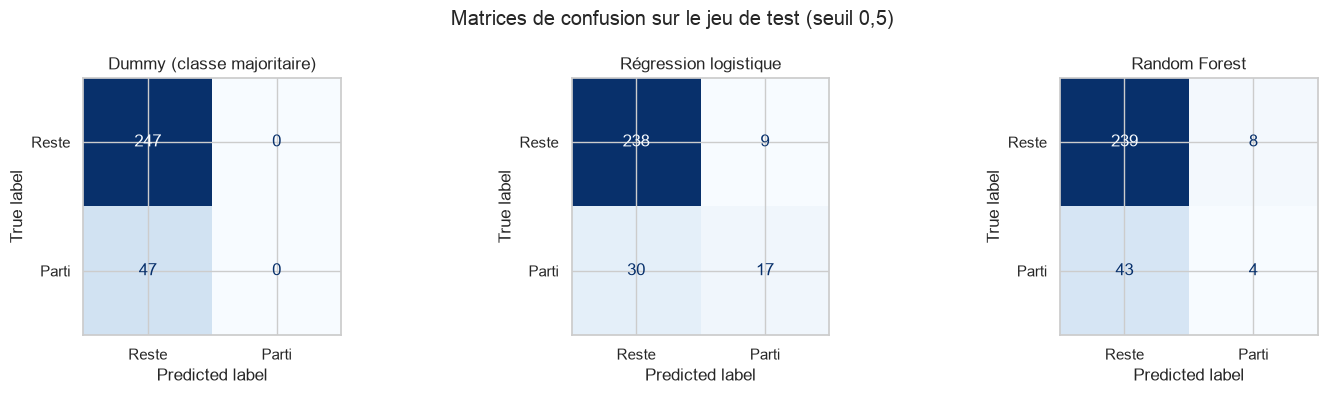

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (nom, modele) in zip(axes, modeles_simples.items()):
    ConfusionMatrixDisplay.from_estimator(modele, X_test, y_test, display_labels=["Reste", "Parti"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nom)
fig.suptitle("Matrices de confusion sur le jeu de test (seuil 0,5)")
fig.tight_layout()
sauver(fig, "09_confusion_etape3")
plt.show()

**Interprétation**

- Le **Dummy** atteint ≈ 84 % d'accuracy sans rien apprendre (il prédit « reste » pour tout le monde) : l'accuracy
  est trompeuse avec des classes déséquilibrées. Son rappel sur les départs est de 0.
- La **régression logistique** détecte une partie des départs avec une bonne précision ; ses scores sont proches
  entre apprentissage et test : peu de sur-apprentissage.
- La **Random Forest** a des scores parfaits sur l'apprentissage et bien plus bas sur le test : elle **sur-apprend**.
  Au seuil 0,5, elle rate la plupart des départs (rappel faible) : le déséquilibre la pousse vers la classe majoritaire.

Le jeu de données est donc « assez linéaire » : un modèle linéaire fait déjà bien. Il faut maintenant traiter
le déséquilibre et choisir un seuil, avec une évaluation plus robuste (validation croisée).

## 4. Prise en compte du déséquilibre des classes

### 4.1 Approche (posée avant de coder)

- **Découpage** : on garde le jeu de test (20 %, stratifié) **de côté jusqu'à la fin**. Toutes les comparaisons se font
  en **validation croisée stratifiée à 5 plis** sur le jeu d'apprentissage.
- **Métriques** : la classe d'intérêt est le **départ** (classe 1). On suit le **rappel** (part des départs détectés),
  la **précision** (part des alertes justes), le F1, et l'**aire sous la courbe précision-rappel** (PR AUC), plus
  informative que la ROC AUC quand la classe positive est rare. On garde l'accuracy pour mémoire seulement.
- **Contexte métier** : rater un départ (faux négatif) coûte plus cher (recrutement, mission perdue) qu'un entretien
  de rétention proposé à quelqu'un qui serait resté (faux positif). On privilégie donc le **rappel**, sans laisser
  la précision s'effondrer : le seuil sera choisi en maximisant le **F2** (qui donne deux fois plus de poids au rappel).
- **Pistes testées** : pondération des classes (`class_weight="balanced"`, ou poids par employé `sample_weight`
  pour le Gradient Boosting qui n'a pas de `class_weight`), sur-échantillonnage (SMOTE), sous-échantillonnage. Le
  rééchantillonnage est placé dans un Pipeline imblearn pour qu'il ne touche **que** les plis d'apprentissage
  (sinon des copies synthétiques d'un employé de validation fuiraient dans l'apprentissage).

In [35]:
VALIDATION_CROISEE = StratifiedKFold(n_splits=5, shuffle=True, random_state=GRAINE)
METRIQUES = {
    "accuracy": "accuracy",
    "precision": "precision",
    "rappel": "recall",
    "f1": "f1",
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}


def comparer_en_validation_croisee(modeles, X, y):
    """Validation croisée stratifiée : moyenne et écart-type de chaque métrique, en apprentissage et en validation."""
    lignes = []
    for nom, modele in modeles.items():
        scores = cross_validate(modele, X, y, cv=VALIDATION_CROISEE, scoring=METRIQUES,
                                return_train_score=True, n_jobs=-1)
        ligne = {"modele": nom}
        for metrique in METRIQUES:
            valeurs = scores[f"test_{metrique}"]
            ligne[f"{metrique} (val)"] = f"{valeurs.mean():.3f} ± {valeurs.std():.3f}"
        ligne["f1 (app)"] = f"{scores['train_f1'].mean():.3f}"
        ligne["pr_auc (app)"] = f"{scores['train_pr_auc'].mean():.3f}"
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("modele")


class GradientBoostingPondere(GradientBoostingClassifier):
    """Gradient Boosting qui pondère lui-même les classes à chaque entraînement.

    GradientBoostingClassifier n'a pas d'option class_weight : on calcule à chaque fit des poids par employé
    n_total / (2 * n_classe), l'équivalent de class_weight="balanced" (un départ compte ~5 fois plus).
    Les poids étant calculés à l'intérieur de fit, ils ne concernent que les plis d'apprentissage : la validation
    croisée et la recherche d'hyperparamètres évaluent toujours sur des données non pondérées.
    """

    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced", y))


def logistique(**options):
    return Pipeline([("scaler", StandardScaler()),
                     ("modele", LogisticRegression(max_iter=2000, random_state=GRAINE, **options))])


def foret(**options):
    return RandomForestClassifier(n_estimators=300, random_state=GRAINE, n_jobs=-1, **options)


def boosting(pondere=True, **options):
    """Gradient Boosting volontairement peu profond (arbres de profondeur 2) pour limiter le sur-apprentissage."""
    reglages = {"learning_rate": 0.05, "n_estimators": 200, "max_depth": 2, "subsample": 0.8}
    reglages.update(options)
    classe = GradientBoostingPondere if pondere else GradientBoostingClassifier
    return classe(random_state=GRAINE, **reglages)


modeles_etape4 = {
    "Dummy": DummyClassifier(strategy="most_frequent"),
    "Logistique": logistique(),
    "Logistique pondérée": logistique(class_weight="balanced"),
    "Random Forest": foret(),
    "RF pondérée": foret(class_weight="balanced", min_samples_leaf=5),
    "RF + SMOTE": PipelineImb([("smote", SMOTE(random_state=GRAINE)), ("modele", foret(min_samples_leaf=5))]),
    "RF + sous-échantillonnage": PipelineImb([("sous_ech", RandomUnderSampler(random_state=GRAINE)),
                                              ("modele", foret(min_samples_leaf=5))]),
    "Gradient Boosting": boosting(pondere=False),
    "Gradient Boosting pondéré": boosting(),
}
comparaison_etape4 = comparer_en_validation_croisee(modeles_etape4, X_train, y_train)
comparaison_etape4

,accuracy (val),precision (val),rappel (val),f1 (val),pr_auc (val),roc_auc (val),f1 (app),pr_auc (app)
modele,,,,,,,,
Dummy,0.838 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.162 ± 0.000,0.500 ± 0.000,0.000,0.162
Logistique,0.891 ± 0.027,0.779 ± 0.158,0.468 ± 0.123,0.576 ± 0.122,0.678 ± 0.069,0.846 ± 0.027,0.648,0.745
Logistique pondérée,0.778 ± 0.025,0.402 ± 0.032,0.732 ± 0.071,0.516 ± 0.022,0.644 ± 0.080,0.834 ± 0.028,0.556,0.708
Random Forest,0.866 ± 0.011,0.896 ± 0.122,0.211 ± 0.094,0.324 ± 0.117,0.548 ± 0.079,0.803 ± 0.030,1.000,1.000
RF pondérée,0.837 ± 0.017,0.498 ± 0.051,0.463 ± 0.083,0.476 ± 0.057,0.539 ± 0.064,0.800 ± 0.031,0.877,0.961
RF + SMOTE,0.851 ± 0.020,0.564 ± 0.108,0.363 ± 0.110,0.435 ± 0.097,0.510 ± 0.084,0.761 ± 0.035,0.829,0.947
RF + sous-échantillonnage,0.762 ± 0.020,0.367 ± 0.021,0.642 ± 0.061,0.465 ± 0.016,0.508 ± 0.064,0.780 ± 0.024,0.626,0.745
Gradient Boosting,0.878 ± 0.011,0.799 ± 0.107,0.347 ± 0.071,0.476 ± 0.067,0.633 ± 0.047,0.828 ± 0.026,0.691,0.872
Gradient Boosting pondéré,0.817 ± 0.027,0.463 ± 0.053,0.653 ± 0.054,0.537 ± 0.029,0.612 ± 0.058,0.817 ± 0.020,0.736,0.868


**Lecture**

- La **pondération des classes** remonte fortement le **rappel** (on détecte beaucoup plus de départs) au prix d'une
  précision plus basse : c'est le compromis recherché, et le **seuil** permettra de le régler finement.
- La **PR AUC** ne dépend pas du seuil : elle mesure la capacité du modèle à **classer** les employés du plus au moins
  à risque. C'est elle qu'on retient pour comparer les modèles et pour le fine-tuning.
- La **Random Forest** sur-apprend (PR AUC d'apprentissage proche de 1, validation nettement plus basse) et reste
  derrière les autres, quelle que soit la méthode de rééquilibrage. SMOTE et le sous-échantillonnage n'apportent
  rien par rapport à la simple pondération (et le sous-échantillonnage jette de l'information).
- Le **Gradient Boosting** (arbres peu profonds construits les uns après les autres pour corriger les erreurs des
  précédents) est le meilleur modèle non linéaire, au niveau de la régression logistique : les données sont en
  bonne partie « linéaires », mais le boosting capte en plus des effets de seuil.
- Les écarts-types entre plis sont de quelques points : chaque pli de validation ne contient qu'une quarantaine
  de départs. Une différence de 0,02 de PR AUC entre deux modèles n'est donc pas significative.

**Choix** : Amandine demande un modèle non linéaire interprété avec SHAP. On retient le **Gradient Boosting pondéré**,
qu'on va optimiser ; la régression logistique reste notre point de comparaison.

### 4.2 Les features créées ont-elles aidé ?
On compare le même Gradient Boosting pondéré avec et sans les 4 features créées à l'étape 2.

In [36]:
FEATURES_CREEES = ["part_carriere_dans_entreprise", "ratio_poste_entreprise",
                   "stagnation_promotion", "revenu_par_niveau"]
pd.concat([
    comparer_en_validation_croisee({"GB pondéré, avec features créées": boosting()}, X_train, y_train),
    comparer_en_validation_croisee({"GB pondéré, sans features créées": boosting()},
                                   X_train.drop(columns=FEATURES_CREEES), y_train),
])

,accuracy (val),precision (val),rappel (val),f1 (val),pr_auc (val),roc_auc (val),f1 (app),pr_auc (app)
modele,,,,,,,,
"GB pondéré, avec features créées",0.817 ± 0.027,0.463 ± 0.053,0.653 ± 0.054,0.537 ± 0.029,0.612 ± 0.058,0.817 ± 0.020,0.736,0.868
"GB pondéré, sans features créées",0.819 ± 0.020,0.462 ± 0.043,0.658 ± 0.086,0.539 ± 0.038,0.622 ± 0.053,0.825 ± 0.016,0.712,0.860


L'écart est inférieur à l'écart-type entre plis : les features créées **n'améliorent pas significativement** la
performance (l'information était déjà présente dans les colonnes d'origine, que les arbres savent combiner).
On les garde car elles ne dégradent rien et sont **lisibles pour les RH** (part de carrière chez TechNova,
stagnation depuis la dernière promotion).

### 4.3 Courbe précision-rappel et choix du seuil

On obtient des probabilités **hors échantillon** pour chaque employé du jeu d'apprentissage (`cross_val_predict` :
chaque probabilité vient d'un modèle qui n'a pas vu cet employé), puis on choisit le seuil qui maximise le F2.
Le jeu de test n'est pas utilisé pour ce choix.

Seuil retenu (F2 max) : 0.43  ->  précision 0.40, rappel 0.74, F2 0.63


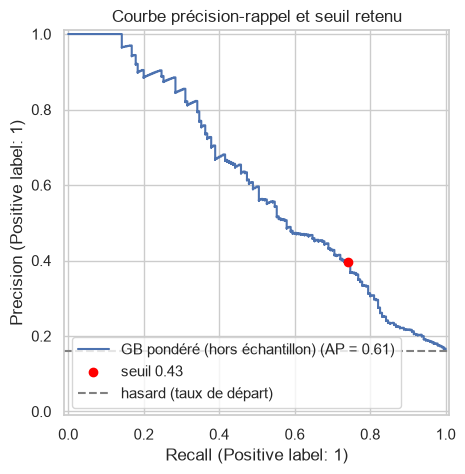

In [37]:
def choisir_seuil(y_vrai, probas, beta=2):
    """Seuil qui maximise le F-beta (beta = 2 : le rappel compte deux fois plus que la précision)."""
    precisions, rappels, seuils = precision_recall_curve(y_vrai, probas)
    precisions, rappels = precisions[:-1], rappels[:-1]   # le dernier point n'a pas de seuil associé
    f_beta = (1 + beta**2) * precisions * rappels / np.clip(beta**2 * precisions + rappels, 1e-12, None)
    meilleur = np.argmax(f_beta)
    return seuils[meilleur], precisions[meilleur], rappels[meilleur], f_beta[meilleur]


def probas_hors_echantillon(modele, X, y):
    """Probabilité de départ de chaque employé, prédite par un modèle entraîné sans lui (validation croisée)."""
    return cross_val_predict(modele, X, y, cv=VALIDATION_CROISEE, method="predict_proba")[:, 1]


probas_oof = probas_hors_echantillon(boosting(), X_train, y_train)
seuil_gb, p, r, f2 = choisir_seuil(y_train, probas_oof)
print(f"Seuil retenu (F2 max) : {seuil_gb:.2f}  ->  précision {p:.2f}, rappel {r:.2f}, F2 {f2:.2f}")

fig, ax = plt.subplots(figsize=(7, 5))
PrecisionRecallDisplay.from_predictions(y_train, probas_oof, ax=ax, name="GB pondéré (hors échantillon)")
ax.scatter(r, p, color="red", zorder=5, label=f"seuil {seuil_gb:.2f}")
ax.axhline(y_train.mean(), color="grey", linestyle="--", label="hasard (taux de départ)")
ax.set(title="Courbe précision-rappel et seuil retenu")
ax.legend()
sauver(fig, "10_courbe_pr_etape4")
plt.show()

**Pourquoi un seuil différent de 0,5 ?** Avec la pondération, les probabilités sont « gonflées » pour la classe
départ ; et surtout 0,5 n'a aucune raison d'être le bon compromis métier. Le point rouge est le seuil où le F2
est maximal : on y détecte une large majorité des départs en acceptant environ 2 fausses alertes pour 1 alerte juste.

## 5. Fine-tuning et interprétation

### 5.1 Recherche d'hyperparamètres
`RandomizedSearchCV` teste 40 combinaisons tirées au hasard, chacune évaluée en validation croisée stratifiée
à 5 plis sur le jeu d'apprentissage, en optimisant la **PR AUC** (`average_precision`). La grille privilégie des
modèles prudents (taux d'apprentissage faibles, arbres peu profonds, feuilles d'au moins 10 employés) car avec
~190 départs en apprentissage, le risque principal est le sur-apprentissage.

In [38]:
grille = {
    "learning_rate": [0.01, 0.02, 0.05],
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [1, 2, 3],
    "subsample": [0.6, 0.8, 1.0],
    "min_samples_leaf": [10, 20, 40],
    "max_features": [None, "sqrt", 0.5],
}
recherche = RandomizedSearchCV(
    GradientBoostingPondere(random_state=GRAINE),
    param_distributions=grille, n_iter=40, scoring="average_precision",
    cv=VALIDATION_CROISEE, random_state=GRAINE, n_jobs=-1, return_train_score=True,
)
recherche.fit(X_train, y_train)
print("Meilleurs hyperparamètres :", recherche.best_params_)
print(f"PR AUC en validation croisée : {recherche.best_score_:.3f}")
(pd.DataFrame(recherche.cv_results_)
   .sort_values("rank_test_score")
   [["params", "mean_train_score", "mean_test_score", "std_test_score"]]
   .head(5).round(3))

Meilleurs hyperparamètres : {'subsample': 1.0, 'n_estimators': 400, 'min_samples_leaf': 40, 'max_features': 0.5, 'max_depth': 1, 'learning_rate': 0.05}
PR AUC en validation croisée : 0.638


,params,mean_train_score,mean_test_score,std_test_score
29,"{'subsample': 1.0, 'n_estimators': 400, 'min_s...",0.742,0.638,0.041
31,"{'subsample': 0.6, 'n_estimators': 400, 'min_s...",0.943,0.636,0.058
12,"{'subsample': 1.0, 'n_estimators': 300, 'min_s...",0.869,0.636,0.057
8,"{'subsample': 0.8, 'n_estimators': 300, 'min_s...",0.963,0.634,0.059
18,"{'subsample': 0.6, 'n_estimators': 400, 'min_s...",0.896,0.630,0.062


**Lecture** : la meilleure combinaison utilise des **arbres de profondeur 1** (une seule coupure par arbre) avec des
feuilles d'au moins 40 employés. Le modèle devient une somme d'effets **par variable**, chacun pouvant être non
linéaire (effets de seuil), mais sans interactions entre variables. C'est cohérent avec le constat de l'étape 3 :
les données sont proches du linéaire, et un modèle plus complexe sur-apprend. L'écart apprentissage / validation
se réduit fortement par rapport au modèle avant tuning.

In [39]:
modele_final = recherche.best_estimator_

# Comparaison en validation croisée : modèle optimisé vs références
comparaison_finale = comparer_en_validation_croisee(
    {"Dummy": DummyClassifier(strategy="most_frequent"),
     "Logistique pondérée": logistique(class_weight="balanced"),
     "GB pondéré (avant tuning)": boosting(),
     "GB pondéré optimisé": modele_final},
    X_train, y_train,
)
comparaison_finale

,accuracy (val),precision (val),rappel (val),f1 (val),pr_auc (val),roc_auc (val),f1 (app),pr_auc (app)
modele,,,,,,,,
Dummy,0.838 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.162 ± 0.000,0.500 ± 0.000,0.000,0.162
Logistique pondérée,0.778 ± 0.025,0.402 ± 0.032,0.732 ± 0.071,0.516 ± 0.022,0.644 ± 0.080,0.834 ± 0.028,0.556,0.708
GB pondéré (avant tuning),0.817 ± 0.027,0.463 ± 0.053,0.653 ± 0.054,0.537 ± 0.029,0.612 ± 0.058,0.817 ± 0.020,0.736,0.868
GB pondéré optimisé,0.792 ± 0.033,0.422 ± 0.046,0.716 ± 0.051,0.528 ± 0.035,0.638 ± 0.041,0.826 ± 0.023,0.597,0.742


In [40]:
# Seuil du modèle optimisé (toujours sur des probabilités hors échantillon du jeu d'apprentissage)
probas_oof_final = probas_hors_echantillon(modele_final, X_train, y_train)
SEUIL, p, r, f2 = choisir_seuil(y_train, probas_oof_final)
print(f"Seuil du modèle final : {SEUIL:.2f}  (validation croisée : précision {p:.2f}, rappel {r:.2f}, F2 {f2:.2f})")

Seuil du modèle final : 0.48  (validation croisée : précision 0.40, rappel 0.75, F2 0.64)


### 5.2 Évaluation finale sur le jeu de test (jamais utilisé jusqu'ici)

In [41]:
resultats_finaux = evaluer_train_test("GB pondéré optimisé, seuil ajusté", modele_final,
                                      X_train, y_train, X_test, y_test, seuil=SEUIL)
probas_test = modele_final.predict_proba(X_test)[:, 1]
print(f"PR AUC test : {average_precision_score(y_test, probas_test):.3f}  |  "
      f"ROC AUC test : {roc_auc_score(y_test, probas_test):.3f}  |  "
      f"F2 test : {fbeta_score(y_test, (probas_test >= SEUIL).astype(int), beta=2):.3f}")
resultats_finaux.set_index("jeu").round(3)

===== GB pondéré optimisé, seuil ajusté : rapport de classification sur le TEST =====
              precision    recall  f1-score   support

   Reste (0)       0.95      0.77      0.85       247
   Parti (1)       0.39      0.77      0.52        47

    accuracy                           0.77       294
   macro avg       0.67      0.77      0.68       294
weighted avg       0.86      0.77      0.80       294

PR AUC test : 0.533  |  ROC AUC test : 0.810  |  F2 test : 0.643


,modele,accuracy,precision,rappel,f1,pr_auc
jeu,,,,,,
apprentissage,"GB pondéré optimisé, seuil ajusté",0.803,0.441,0.821,0.574,0.732
test,"GB pondéré optimisé, seuil ajusté",0.772,0.391,0.766,0.518,0.533


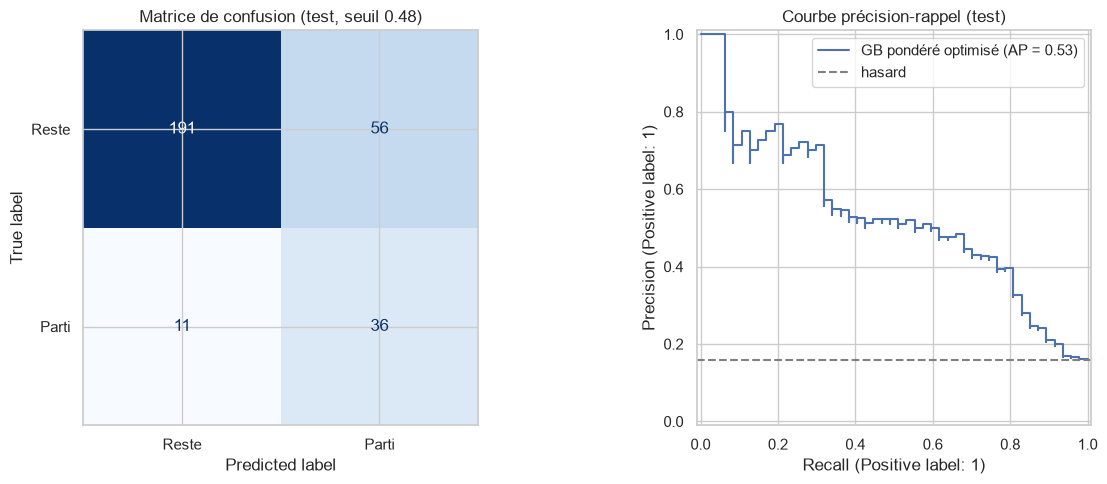

Sur 294 employés de test (47 départs) : 36 départs détectés, 11 manqués, 56 fausses alertes, 191 employés restés bien classés.


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, (probas_test >= SEUIL).astype(int),
                                        display_labels=["Reste", "Parti"], cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Matrice de confusion (test, seuil {SEUIL:.2f})")
PrecisionRecallDisplay.from_predictions(y_test, probas_test, ax=axes[1], name="GB pondéré optimisé")
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", label="hasard")
axes[1].set_title("Courbe précision-rappel (test)")
axes[1].legend()
fig.tight_layout()
sauver(fig, "11_evaluation_finale")
plt.show()

vn, fp, fn, vp = confusion_matrix(y_test, (probas_test >= SEUIL).astype(int)).ravel()
print(f"Sur {len(y_test)} employés de test ({y_test.sum()} départs) : {vp} départs détectés, {fn} manqués, "
      f"{fp} fausses alertes, {vn} employés restés bien classés.")

In [43]:
# Point de comparaison honnête : la régression logistique pondérée, avec la même méthode de seuil, sur le même test
logistique_finale = logistique(class_weight="balanced")
seuil_logistique, *_ = choisir_seuil(y_train, probas_hors_echantillon(logistique_finale, X_train, y_train))
logistique_finale.fit(X_train, y_train)
probas_test_logistique = logistique_finale.predict_proba(X_test)[:, 1]
pd.DataFrame({
    modele: {
        "PR AUC": average_precision_score(y_test, probas),
        "ROC AUC": roc_auc_score(y_test, probas),
        "précision": precision_score(y_test, (probas >= seuil).astype(int)),
        "rappel": recall_score(y_test, (probas >= seuil).astype(int)),
        "F2": fbeta_score(y_test, (probas >= seuil).astype(int), beta=2),
        "seuil": seuil,
    }
    for modele, probas, seuil in [("GB pondéré optimisé", probas_test, SEUIL),
                                  ("Logistique pondérée", probas_test_logistique, seuil_logistique)]
}).round(3)

,GB pondéré optimisé,Logistique pondérée
PR AUC,0.533,0.534
ROC AUC,0.810,0.816
précision,0.391,0.375
rappel,0.766,0.702
F2,0.643,0.598
seuil,0.482,0.496


**Interprétation de la performance**

- Le modèle **détecte environ 3 départs sur 4** du jeu de test, avec une précision environ 2,5 fois supérieure
  au hasard (le hasard donnerait une précision égale au taux de départ, ≈ 16 %).
- Les métriques au seuil (rappel, précision, F2) sont proches entre apprentissage et test : **pas de sur-apprentissage
  marqué**. La PR AUC du test (≈ 0,53) est un peu plus basse qu'en validation croisée (≈ 0,64) : avec 47 départs
  seulement, la PR AUC d'un seul jeu de test varie beaucoup, et la régression logistique baisse exactement autant,
  ce qui indique un jeu de test un peu plus difficile plutôt qu'un défaut du modèle.
- **Honnêtement**, le Gradient Boosting et la régression logistique font jeu égal (PR AUC et ROC AUC quasi
  identiques ; le boosting a un meilleur rappel au seuil choisi). Le gain du non-linéaire est modeste : on le garde
  parce qu'il capte des effets de seuil (visibles avec SHAP) et répond à la demande d'Amandine ; en production, la
  logistique serait une alternative plus simple et tout aussi fiable.
- Le prix du rappel élevé est un nombre important de **fausses alertes** : c'est acceptable si l'action déclenchée
  est légère (un entretien RH, un point de carrière), pas si elle est coûteuse. Le seuil peut être remonté si les RH
  préfèrent moins d'alertes.
- Le modèle sert d'**outil de priorisation** et de support à l'interprétation, pas de prédicteur individuel
  infaillible : 1 470 employés et 237 départs, c'est peu.

### 5.3 Feature importance globale : trois méthodes comparées

1. **Importance native** du Gradient Boosting (baisse d'impureté apportée par chaque variable dans les arbres) :
   rapide, mais biaisée vers les variables continues à nombreuses valeurs et sans indication de sens.
2. **Permutation importance** (scikit-learn), calculée sur le **jeu de test** : de combien la PR AUC baisse si on
   mélange une colonne au hasard (le lien entre cette colonne et la cible est alors cassé).
3. **SHAP** (TreeExplainer) : contribution moyenne absolue de chaque feature à la probabilité prédite.

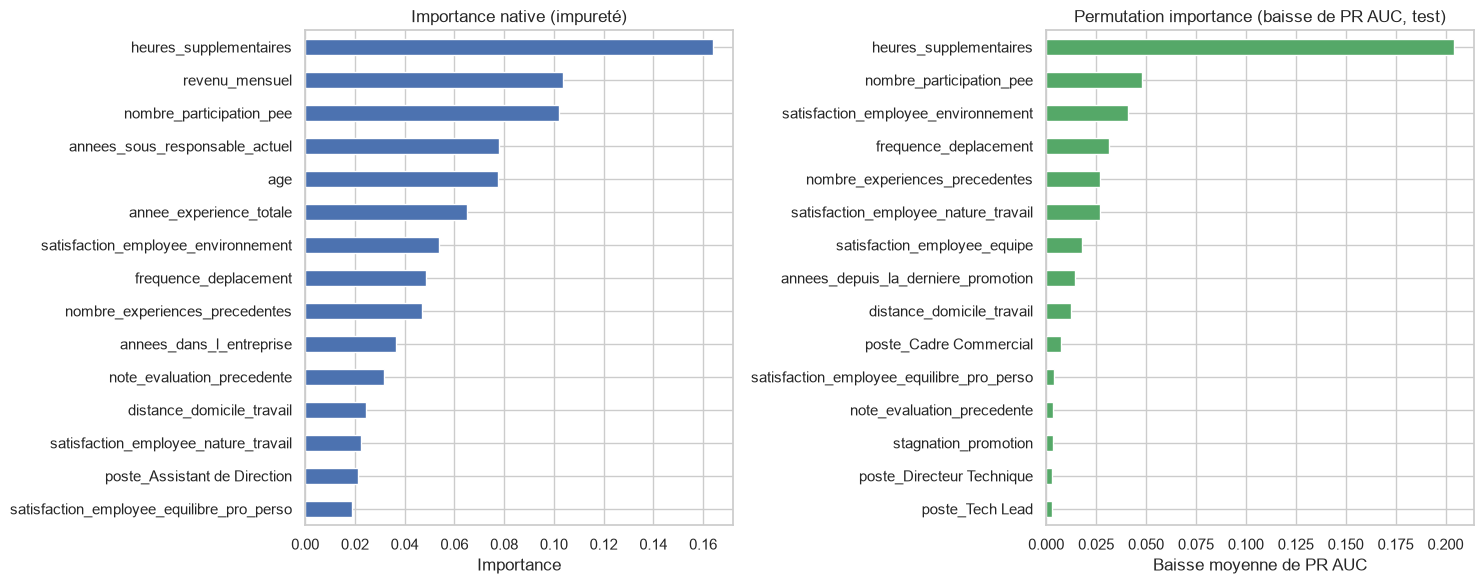

In [44]:
importance_native = pd.Series(modele_final.feature_importances_, index=X.columns, name="native")

permutation = permutation_importance(modele_final, X_test, y_test, scoring="average_precision",
                                     n_repeats=30, random_state=GRAINE, n_jobs=-1)
importance_permutation = pd.Series(permutation.importances_mean, index=X.columns, name="permutation")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
importance_native.sort_values().tail(15).plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set(title="Importance native (impureté)", xlabel="Importance")
importance_permutation.sort_values().tail(15).plot.barh(ax=axes[1], color="#55A868")
axes[1].set(title="Permutation importance (baisse de PR AUC, test)", xlabel="Baisse moyenne de PR AUC")
fig.tight_layout()
sauver(fig, "12_importance_native_permutation")
plt.show()

### 5.4 Valeurs de Shapley (SHAP)

**Rappel du sens** : pour un employé, la valeur SHAP d'une feature est sa contribution à l'écart entre la
probabilité prédite pour cet employé et la probabilité moyenne prédite par le modèle (valeur de base). Une valeur
positive pousse vers le **départ**, une valeur négative vers le **maintien**. La valeur de base plus la somme des
valeurs SHAP redonne exactement la probabilité prédite.

On demande au `TreeExplainer` d'exprimer les contributions **en probabilité** (`model_output="probability"`), avec
un échantillon du jeu d'apprentissage comme population de référence : c'est plus parlant qu'en log-odds pour une audience RH.

In [45]:
# Population de référence : 100 employés tirés du jeu d'apprentissage (suffisant et beaucoup plus rapide)
reference = X_train.sample(100, random_state=GRAINE)
explainer = shap.TreeExplainer(modele_final, data=reference, model_output="probability")
shap_depart = explainer(X_test)             # une valeur par employé du test et par feature
print("Valeur de base (probabilité moyenne prédite sur la population de référence) :",
      round(float(shap_depart.base_values[0]), 3))

# Vérification : valeur de base + somme des valeurs SHAP = probabilité prédite
reconstruction = shap_depart.base_values + shap_depart.values.sum(axis=1)
ecart_max = np.abs(reconstruction - modele_final.predict_proba(X_test)[:, 1]).max()
print(f"Écart maximal entre la reconstruction SHAP et la probabilité du modèle : {ecart_max:.1e}")

Valeur de base (probabilité moyenne prédite sur la population de référence) : 0.416
Écart maximal entre la reconstruction SHAP et la probabilité du modèle : 5.0e-09


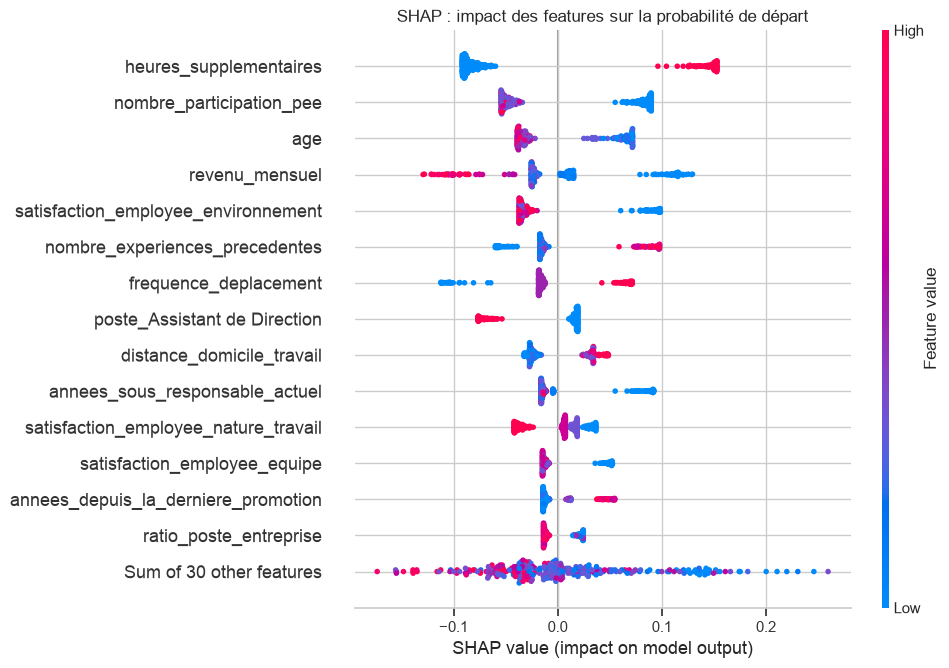

In [46]:
plt.figure()
shap.plots.beeswarm(shap_depart, max_display=15, show=False)
plt.title("SHAP : impact des features sur la probabilité de départ")
sauver(plt.gcf(), "13_shap_beeswarm")
plt.show()

**Lire le beeswarm** : une ligne par feature, classées de la plus à la moins importante ; un point par employé ;
en abscisse, l'effet sur la probabilité de départ ; en couleur, la valeur de la feature (rouge = élevée, bleu = basse).
Exemple : pour `heures_supplementaires`, les points rouges (= 1) sont à droite : faire des heures supplémentaires
augmente la probabilité de départ prédite.

In [47]:
importance_shap = pd.Series(np.abs(shap_depart.values).mean(axis=0), index=X.columns, name="shap")

comparaison_importances = pd.concat([importance_native, importance_permutation, importance_shap], axis=1)
rangs = comparaison_importances.rank(ascending=False).astype(int).add_prefix("rang_")
tableau_importances = pd.concat([comparaison_importances.round(4), rangs], axis=1).sort_values("rang_shap")
tableau_importances.head(15)

,native,permutation,shap,rang_native,rang_permutation,rang_shap
heures_supplementaires,0.1638,0.2041,0.0999,1,1,1
nombre_participation_pee,0.1021,0.0480,0.0640,3,2,2
age,0.0775,0.0001,0.0454,5,18,3
revenu_mensuel,0.1037,0.0017,0.0447,2,16,4
satisfaction_employee_environnement,0.0538,0.0409,0.0444,7,3,5
nombre_experiences_precedentes,0.0469,0.0269,0.0358,9,5,6
frequence_deplacement,0.0486,0.0313,0.0332,8,4,7
poste_Assistant de Direction,0.0212,-0.0115,0.0305,14,40,8
distance_domicile_travail,0.0244,0.0124,0.0290,12,9,9
annees_sous_responsable_actuel,0.0779,-0.0382,0.0287,4,43,10


In [48]:
# Les 10 premières features selon chaque méthode : lesquelles sont communes aux trois ?
top10 = {methode: set(comparaison_importances[methode].nlargest(10).index) for methode in comparaison_importances}
print("Communes aux 3 méthodes :", sorted(top10["native"] & top10["permutation"] & top10["shap"]))
print("Dans le top 10 SHAP seulement :", sorted(top10["shap"] - top10["native"] - top10["permutation"]))

Communes aux 3 méthodes : ['frequence_deplacement', 'heures_supplementaires', 'nombre_experiences_precedentes', 'nombre_participation_pee', 'satisfaction_employee_environnement']
Dans le top 10 SHAP seulement : ['poste_Assistant de Direction']


**Convergences et divergences entre les trois méthodes**

- Les trois méthodes s'accordent sur un **noyau dur** de variables (affiché ci-dessus) : heures supplémentaires,
  rémunération, ancienneté / âge, actionnariat salarié (PEE), satisfaction, statut marital.
- L'importance **native** surévalue les variables continues à beaucoup de valeurs (revenu, âge, distance, ratios) :
  elles offrent plus de points de coupure aux arbres. C'est un biais connu de l'importance par impureté.
- La **permutation** est calculée sur peu de départs (47 dans le test) : elle est bruitée, et deux variables très
  corrélées (ex. âge et expérience totale) se « couvrent » l'une l'autre : mélanger l'une ne coûte presque rien si
  l'autre est encore là. Certaines importances tombent ainsi à 0, voire deviennent légèrement négatives.
- **SHAP** répartit équitablement l'effet entre variables et donne en plus le **sens** de l'effet : c'est la
  méthode la plus utile pour expliquer le modèle aux RH.

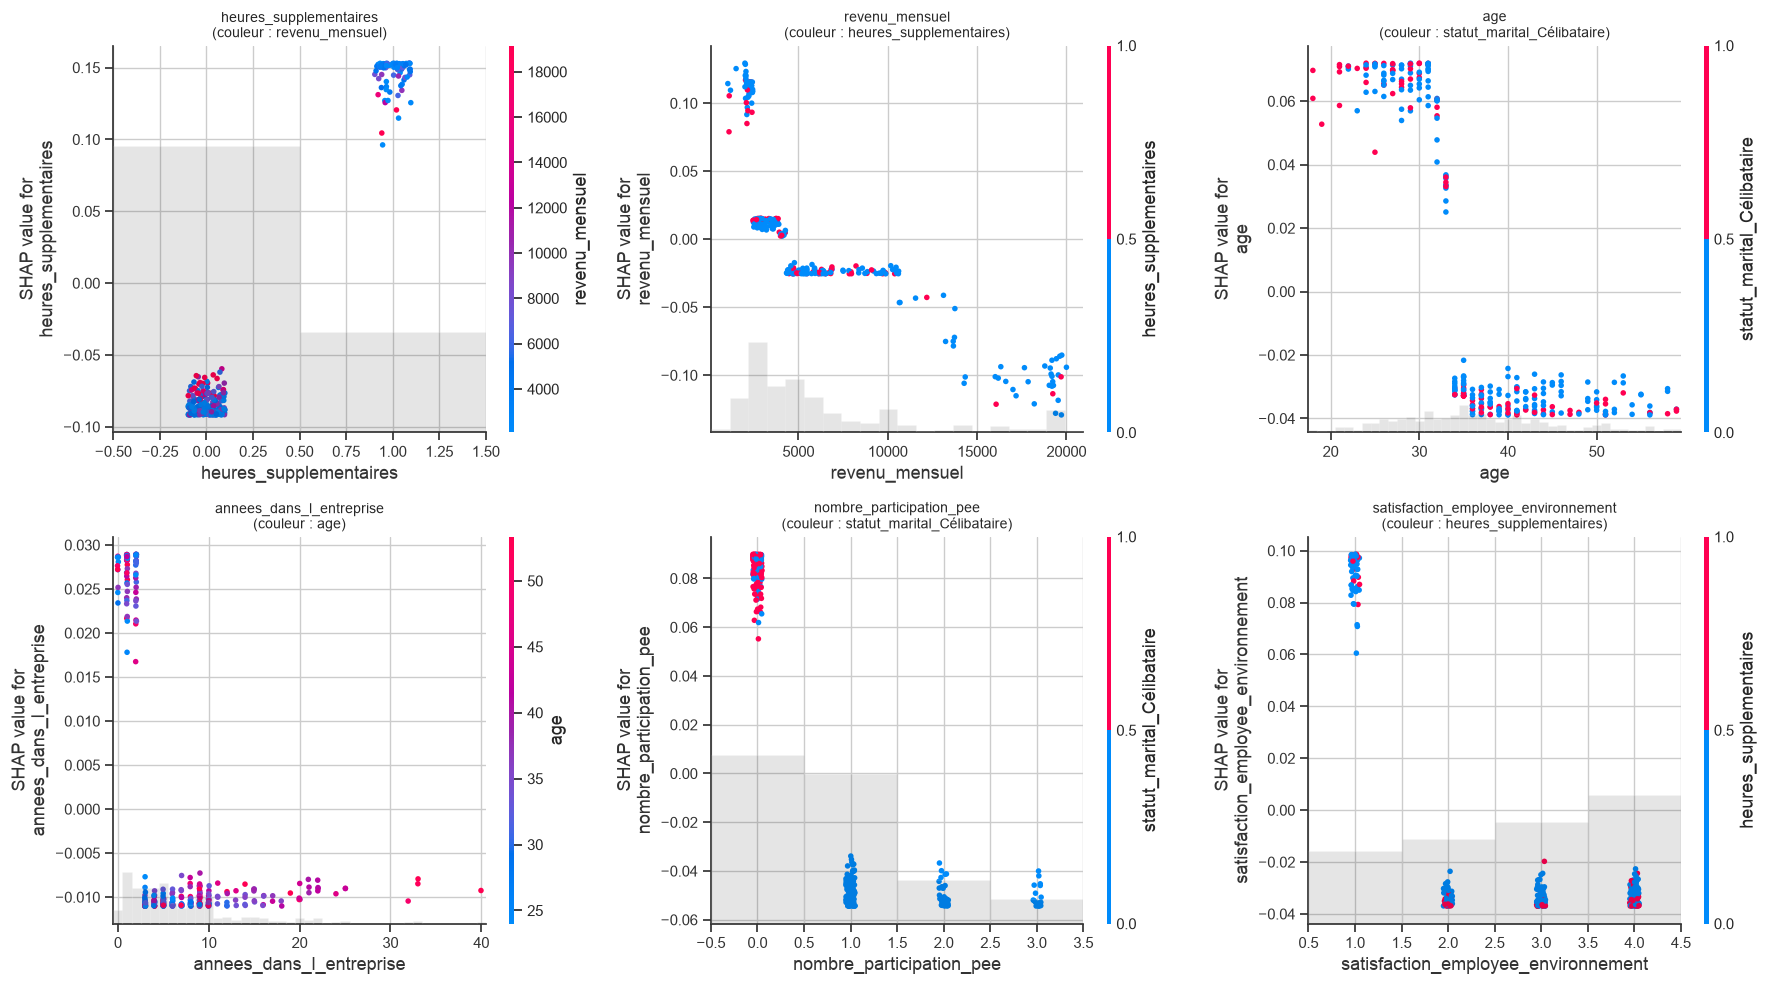

In [49]:
# Comprendre le sens des valeurs de Shapley : nuages de points, avec une seconde variable en couleur
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, (feature, couleur) in zip(axes.flat, [
    ("heures_supplementaires", "revenu_mensuel"),
    ("revenu_mensuel", "heures_supplementaires"),
    ("age", "statut_marital_Célibataire"),
    ("annees_dans_l_entreprise", "age"),
    ("nombre_participation_pee", "statut_marital_Célibataire"),
    ("satisfaction_employee_environnement", "heures_supplementaires"),
]):
    shap.plots.scatter(shap_depart[:, feature], color=shap_depart[:, couleur], ax=ax, show=False)
    ax.set_title(f"{feature}\n(couleur : {couleur})", fontsize=10)
fig.tight_layout()
sauver(fig, "14_shap_scatter")
plt.show()

**Lecture des nuages de points SHAP** (axe vertical = effet sur la probabilité de départ, en points de probabilité)

- `heures_supplementaires` : faire des heures supplémentaires ajoute environ **+15 points** de probabilité, ne pas
  en faire en retire environ 9. C'est l'effet le plus fort du modèle.
- `revenu_mensuel` : effet **en paliers**, nettement non linéaire. Sous ~2 500, environ +11 points ; entre 2 500 et
  4 500, effet quasi nul ; au-delà de ~10 000, environ −10 points. Une régression logistique n'aurait qu'une pente.
- `age` : un seuil net vers **33 ans** : en dessous, environ +7 points ; au-dessus, environ −4 points.
- `annees_dans_l_entreprise` : un petit surcroît de risque sur les **deux premières années** (environ +3 points).
- `nombre_participation_pee` : ne participer à **aucun** plan d'épargne entreprise ajoute environ +8 points.
- `satisfaction_employee_environnement` : seule la note **1** compte (environ +9 points) ; de 2 à 4, l'effet est le même.
- Les couleurs (seconde variable) sont mélangées à chaque niveau : **pas d'interaction**, ce qui est attendu avec des
  arbres de profondeur 1 (chaque arbre ne regarde qu'une variable).

**Attention à une confusion dans les données** : les 470 célibataires ont **tous** 0 participation au PEE (aucun
célibataire ne participe au PEE dans l'extrait). Le modèle attribue l'effet au PEE, mais il est impossible de
séparer « célibataire » de « sans PEE » avec ces données : il faut présenter ces deux facteurs ensemble aux RH.

### 5.5 Feature importance locale : explications individuelles (Waterfall)
On prend des employés du jeu de test des **deux classes**, un cas **typique** (probabilité médiane) dans chacune
des quatre cases de la matrice de confusion : départ bien détecté, employé resté bien classé, employé resté mais
signalé (fausse alerte), départ manqué (limites du modèle).

Départ bien détecté (vrai positif) : employé n°47, probabilité prédite 0.66 (seuil 0.48)


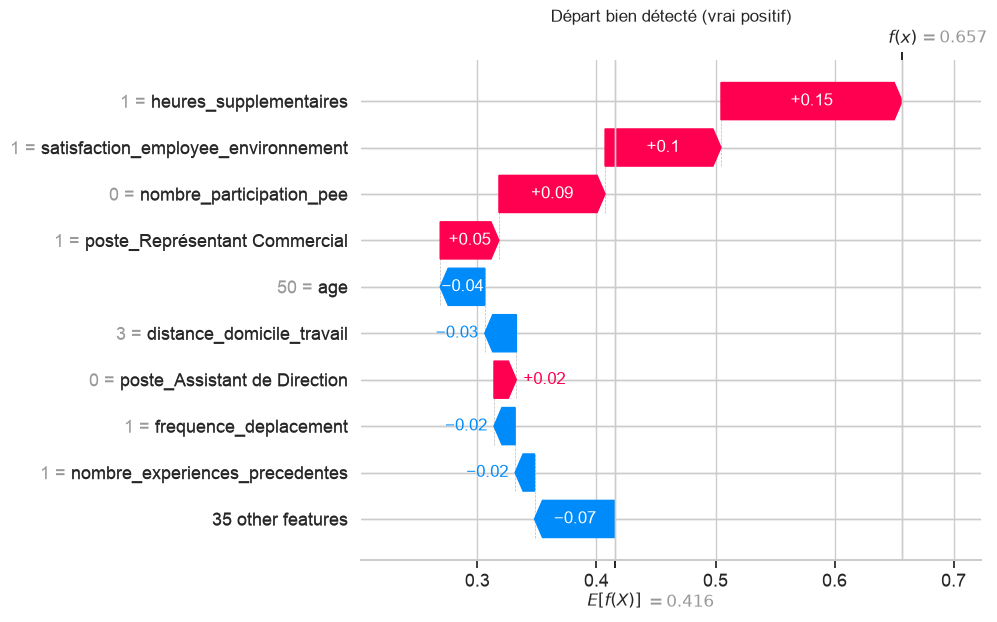

Employé resté, bien classé (vrai négatif) : employé n°1358, probabilité prédite 0.27 (seuil 0.48)


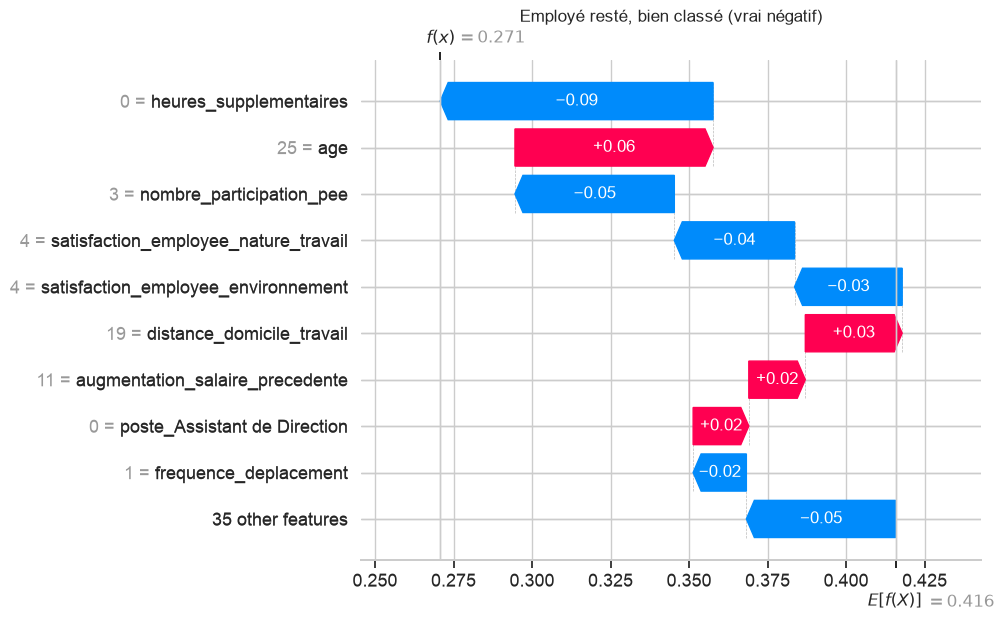

Employé resté mais signalé (faux positif) : employé n°1641, probabilité prédite 0.60 (seuil 0.48)


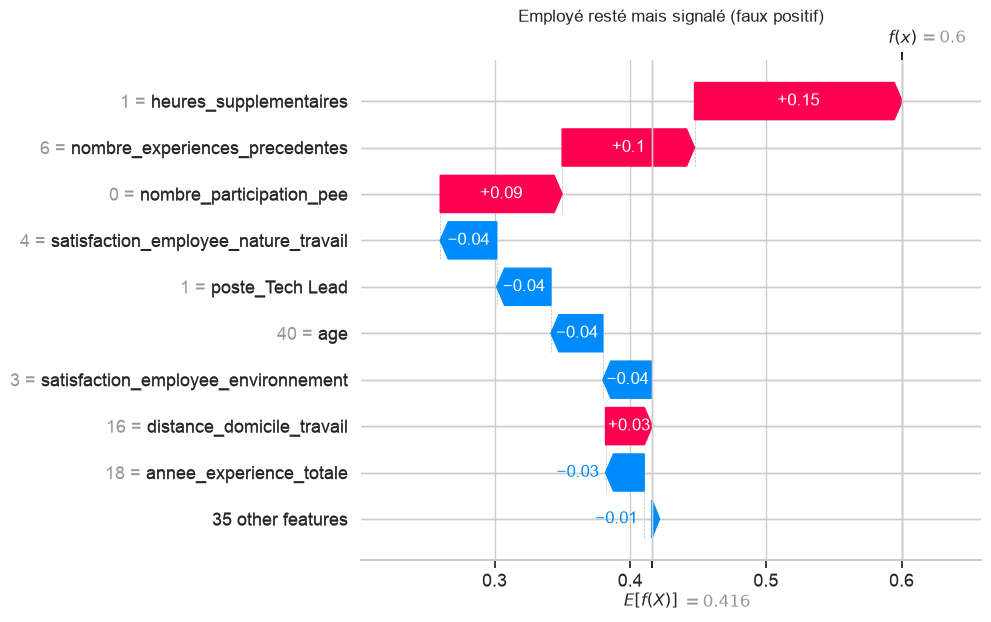

Départ manqué (faux négatif) : employé n°510, probabilité prédite 0.31 (seuil 0.48)


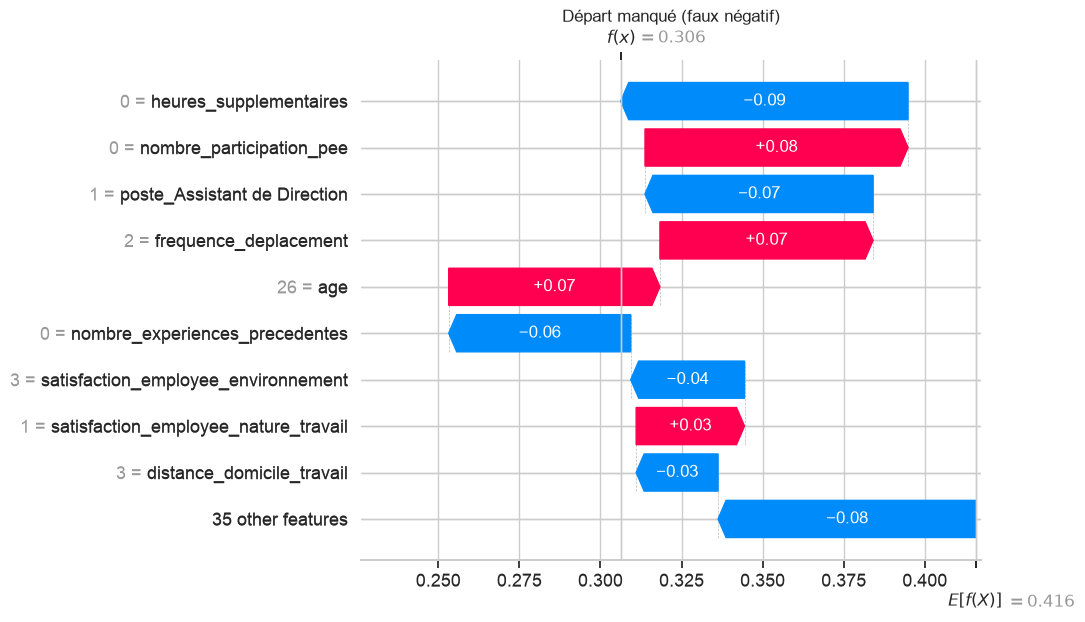

In [50]:
resultats_test = pd.DataFrame({"reel": y_test.values, "proba": probas_test}, index=X_test.index)
resultats_test["prediction"] = (resultats_test["proba"] >= SEUIL).astype(int)
position = {indice: i for i, indice in enumerate(X_test.index)}

def employe_median(groupe):
    """Employé dont la probabilité est la plus proche de la médiane du groupe : un cas typique, pas extrême."""
    return (groupe["proba"] - groupe["proba"].median()).abs().idxmin()


exemples = {
    "Départ bien détecté (vrai positif)": employe_median(resultats_test.query("reel == 1 and prediction == 1")),
    "Employé resté, bien classé (vrai négatif)": employe_median(resultats_test.query("reel == 0 and prediction == 0")),
    "Employé resté mais signalé (faux positif)": employe_median(resultats_test.query("reel == 0 and prediction == 1")),
    "Départ manqué (faux négatif)": employe_median(resultats_test.query("reel == 1 and prediction == 0")),
}
for numero, (titre, indice) in enumerate(exemples.items(), start=1):
    print(f"{titre} : employé n°{df_central.loc[indice, 'id_employee']}, "
          f"probabilité prédite {resultats_test.loc[indice, 'proba']:.2f} (seuil {SEUIL:.2f})")
    plt.figure()
    shap.plots.waterfall(shap_depart[position[indice]], max_display=10, show=False)
    plt.title(titre)
    sauver(plt.gcf(), f"15_waterfall_{numero}")
    plt.show()

In [51]:
# Les caractéristiques réelles des 4 employés, pour relier le graphique aux données
colonnes_utiles = ["age", "revenu_mensuel", "heures_supplementaires", "annees_dans_l_entreprise",
                   "nombre_participation_pee", "statut_marital", "poste", "satisfaction_employee_environnement",
                   "satisfaction_employee_equilibre_pro_perso", "frequence_deplacement", "distance_domicile_travail"]
fiche_exemples = df_central.loc[list(exemples.values()), ["id_employee"] + colonnes_utiles]
fiche_exemples.index = list(exemples.keys())
fiche_exemples.T

,Départ bien détecté (vrai positif),"Employé resté, bien classé (vrai négatif)",Employé resté mais signalé (faux positif),Départ manqué (faux négatif)
id_employee,47,1358,1641,510
age,50,25,40,26
revenu_mensuel,2683,3669,7945,3102
heures_supplementaires,1,0,1,0
annees_dans_l_entreprise,3,3,4,6
nombre_participation_pee,0,3,0,0
statut_marital,Marié(e),Marié(e),Célibataire,Célibataire
poste,Représentant Commercial,Consultant,Tech Lead,Assistant de Direction
satisfaction_employee_environnement,1,4,3,3
satisfaction_employee_equilibre_pro_perso,3,2,2,3


**Lecture d'un waterfall** : on part en bas de la valeur de base E[f(x)] (probabilité moyenne) ; chaque barre
rouge ajoute du risque, chaque barre bleue en retire ; on arrive en haut à la probabilité de l'employé f(x).

- Le **départ bien détecté** cumule plusieurs facteurs de risque à la fois : c'est l'accumulation qui fait monter
  la probabilité, pas un facteur isolé.
- L'**employé resté bien classé** cumule des facteurs protecteurs (pas d'heures supplémentaires, revenu et
  ancienneté élevés, participation au PEE).
- La **fausse alerte** ressemble en tout point à un profil de départ : pour les RH, c'est une personne « à risque »
  qui mérite quand même un échange.
- Le **départ manqué** a un profil de personne qui reste : sa raison de partir n'est pas dans nos données
  (projet personnel, offre externe, déménagement…). C'est une limite structurelle, pas un défaut de réglage.

## 6. Synthèse

**Données** : 3 extraits (SIRH, évaluations, sondage) de 1 470 employés, rapprochés par jointure interne sur
l'identifiant employé ; 3 colonnes constantes supprimées, 3 colonnes texte converties ; 16 % de départs.

**Modélisation** : Gradient Boosting pondéré (poids d'équilibrage des classes), hyperparamètres optimisés par
recherche aléatoire en validation croisée stratifiée à 5 plis (critère : PR AUC), seuil de décision choisi sur la
courbe précision-rappel pour maximiser le F2 (rappel prioritaire). Évaluation finale sur un jeu de test stratifié
jamais utilisé avant.

**Causes potentielles de démission (SHAP)** : heures supplémentaires (de loin le premier facteur), rémunération
basse (effet de seuil sous ~2 500), âge inférieur à ~33 ans, absence de participation au PEE (confondue avec le
célibat dans les données), satisfaction de l'environnement de travail à 1, nombreux employeurs précédents,
déplacements fréquents, distance domicile-travail, peu d'années sous le même responsable.

**Leviers actionnables pour les RH** : piloter la charge (heures supplémentaires), revoir les grilles des premiers
niveaux de salaire, suivre de près les moins de 33 ans et les deux premières années, promouvoir le PEE (notamment
auprès des célibataires, qui n'y participent jamais), traiter toute note de satisfaction à 1 comme un signal d'alerte.

**Limites** : corrélations et non causalité ; petit volume (237 départs) ; une seule photo dans le temps ; pas
d'information sur le marché externe ni sur les raisons déclarées des départs.